# Nucleosome (TIS-DNA + SOP-histone, explicit ions) — analysis notebook

**Design rules**
1. Every analysis block is followed by an *Experimental comparison* note saying what it is compared to and what the caveats are.
2. Native contacts are defined from the **original crystal structure (2CV5)** after converting it to your CG representation (DNA → P/S/B beads as in `AA2TIS.py`, histones → CA beads as in `AA2CG.py`). Because 2CV5 does not contain the tails you added, only the resolved histone **core** is used, automatically.
3. New per-frame analyses are added by writing one function with the `@observable()` decorator (see the last cell). Nothing else has to change.
4. **Wrapping and handedness are measured without assuming the crystal register or handedness** (`n_close`, `u5c`, `u3c`, `hand*`). The native-contact quantities (`Q`, `n_wrap`, `u5`, `u3`) only see wrapping that reproduces the crystal (left-handed, crystal register) and are kept for comparison.

**Run order:** config → reference → mapping → observables → run → helpers → analysis cells.

**What changed in this version (all tested on 2CV5.pdb, dna_initial.pdb and a 24-frame DCD slice)**
* `make_static`: the simulation topology numbers residues *per bead*; nucleotides are now counted via sugar beads (the old code stopped with a length assertion). Added checks: bp pairing on the crystal and on the topology frame, ≥ 95 % histone residue-name match, box neutrality with the model charges (phosphate −0.6 e).
* DCDs carry no unit cell: `BOX_FALLBACK` (700 Å) is used when the DCD has none.
* The DNA in the simulations wraps as a **right-handed** superhelix, which native-contact `Q` cannot see (Q ≈ 0). New handedness-agnostic wrapping measure + per-frame handedness classifier (own-axis helix fit, validated on the crystal: LEFT) and a secondary mirror-image shape test.
* Ion shell volumes are computed **per frame** (before they came from the first 8 ion frames, i.e. the extended starting DNA); ion frames whose sampling cube does not fit the box are skipped instead of crashing.
* Ion-atmosphere ratio had the wrong sign and used the wrong charge; the anion bar was plotted negative; both fixed (charges from the model).
* Cache key now hashes every parameter and the input files; incomplete DCD lists are skipped, not silently analysed.
* Production window starts after the DNA first *stays* wrapped (`USE_WRAP_TIME`), not just after 20 % of the run.
* Dashed reference lines now come from the 2CV5 CG structure analysed with the same definitions (`CRYS`).
* §9 compares Mg²⁺ at Mn²⁺ sites using *base* beads and guanines as the control (Mn²⁺ sits on N7/O6, not on phosphates).

In [1]:
import os, json, pickle, warnings, hashlib
from collections import defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
try:
    import MDAnalysis as mda
except ImportError:
    mda = None   # only needed for the trajectory-reading cells
warnings.filterwarnings("ignore", category=DeprecationWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

In [3]:
# ───────────────────────────── CONFIG ─────────────────────────────
AA_PDB          = "2CV5.pdb"                 # original all-atom structure (path on your machine)
DNA_CHAINS      = ["I", "J"]                 # 2CV5: 146-bp palindromic DNA
HISTONE_CHAINS  = list("ABCDEFGH")

# ── native protein(core)–DNA contacts, defined on the CG crystal structure ──
# NOTE: these only "see" wrapping in the crystal register AND crystal (left) handedness. For handedness-agnostic
# wrapping use the R_CLOSE-based quantities below (n_close, u5c, u3c, n_wrap_c).
R_NAT           = 8.0      # Å, CA–DNA-bead distance in the crystal CG model (see sensitivity cell)
NAT_DNA_BEADS   = ("P", "S", "B")
GAMMA           = 1.2      # contact counted as formed if d < GAMMA * d0
BOUND_FRAC      = 0.5      # a bp counts as "bound" if >= this fraction of its native contacts are formed

# ── handedness-agnostic wrapping + handedness classification ──
R_CLOSE         = 12.0     # Å: a DNA bead is "on the core" if a histone-core CA bead is within this distance
MIN_CLOSE_BEADS = 2        # a bp is "core-bound" if >= this many of its (up to 6) beads are on the core
WRAP_FRAC_MIN   = 0.75     # a frame is "wrapped" if n_close >= this fraction of the crystal's n_close
HAND_MIN_BP     = 40       # handedness needs >= this many bp between first and last core-bound bp ...
HAND_MIN_SPAN   = 360.0    # ... and a superhelical span of >= this many degrees (otherwise: NaN = undefined)
HAND_MIN_PITCH  = 5.0      # |signed pitch| (Å/turn) below this -> 0 = "ambiguous"
MIRROR_MARGIN   = 5.0      # Å: secondary classifier; mirror-image fit to the crystal path must beat the proper fit by this
SHAPE_MAX       = 20.0     # Å: secondary classifier gives no verdict if even the best fit is worse than this

TEMP            = 300.0    # K (use the Temp value from your input json)
KB              = 0.0019872041   # kcal/mol/K
KT              = KB * TEMP

# ── periodic box ──
# Your DCDs carry NO unit cell (ts.dimensions is None) but the coordinates are wrapped into [0, 700] Å.
# This box is used whenever the DCD has none. If the DCD has a box, that one wins. Set None to disable (no ion analysis then).
BOX_FALLBACK    = (700.0, 700.0, 700.0)   # Å  -- CONFIRM this is your simulation box

# ── model charges (e) — used for the neutrality check and the ion-atmosphere ratios ──
Q_PHOSPHATE     = -0.6     # TIS-DNA effective phosphate charge
HISTONE_Q       = {"LYS": +1.0, "ARG": +1.0, "ASP": -1.0, "GLU": -1.0, "HIS": +1.0}
# ^ HIS = +1 is an ASSUMPTION (for dna_initial.pdb it is the value that makes the box exactly neutral: -174 + 130 + 18 = -26 vs ions +26).
#   Check it against your force field. Section 2 prints the neutrality check; it should read ~0.

# ── sampling ──
STRIDE          = 10       # analyse every STRIDE-th frame
ION_EVERY       = 10       # run the (expensive) ion analysis every ION_EVERY-th analysed frame
EQUIL_FRAC      = 0.2      # discard at least the first 20 % of each replica ...
USE_WRAP_TIME   = True     # ... and everything before the DNA first becomes wrapped and STAYS wrapped (below)
WRAP_SUSTAIN    = 5        # "stays wrapped" = this many consecutive analysed frames with n_close >= WRAP_FRAC_MIN * crystal
FRAMES_TO_TIME  = None     # e.g. 1e-3 to convert frame index to some time unit; None -> frames

# ── ions ──
ION_RESNAMES    = {"K": ("K",), "Cl": ("CL",), "Mg": ("MG",)}
ION_Q           = {"K": +1, "Cl": -1, "Mg": +2}
ION_SURFACE     = "complex"   # "complex" (DNA+all histone beads) or "dna"; distance-to-nearest-bead shells
R_MAX, DR       = 100.0, 2.0  # Å, shell range / width for excess-ion profiles (R_MAX is also the 'bulk' boundary)
R_PLATEAU       = 50.0     # Å, where excess counts are read off (should be on the plateau)
R_LOC           = 10.0     # Å, sphere around each phosphate for local ion concentration
R_BASE_LOC      = 8.0      # Å, sphere around each base bead (crystallographic Mn2+ sits on base N7/O6, not on phosphate)
R_COND          = 7.0      # Å, "condensed" ions = within this distance of any phosphate
N_MC            = 150000   # Monte-Carlo points per ion frame for the shell volumes (volumes are computed PER FRAME)

FRET_PAIRS = [(0, 145), (10, 135)]   # (bp_i, bp_j), 0-based bp index along the DNA; edit to mimic dye positions

# data: one entry per condition (use this for the Mg scan); each replica = list of DCDs concatenated in order
BASE = "/data/cg_dna_histone/combined/Mg8"
def _dcds(sim, run):
    # ASSUMPTION: 4_day_run_2 continues 4_day_run_1 for the same sim/run. Change if that is not true.
    return [f"{BASE}/{s}/nucleosome_sim_{sim}/run{run}/dna_traj.dcd" for s in ("4_day_run_1", "4_day_run_2")]
CONDITIONS = {
    "baseline": dict(
        mg_mM=None,                                   # fill in for the Mg scan
        top=f"{BASE}/4_day_run_1/nucleosome_sim_1/run1/dna_initial.pdb",
        replicas={f"sim{s}_run{r}": _dcds(s, r) for s in (1, 2, 3, 4) for r in (1, 2)},
    ),
}
ANALYSIS_COND = None       # condition or handedness group used by §5–§10, e.g. "baseline[RIGHT]" (created in §5b if replicas differ); None = first condition
REQUIRE_ALL_FILES = True    # a replica whose DCD list is incomplete is SKIPPED (never silently analysed from a partial list)
CACHE_DIR, FORCE_RECOMPUTE = "analysis_cache", False   # cache key hashes ALL parameters above + file names/sizes
PROT_OFFSET_OVERRIDE = {}   # e.g. {"D": 4}: sim_resid + offset = 2CV5 resid, only if auto-detection fails

## 1. Reference: 2CV5 → CG (same grouping as `AA2TIS.py` / `AA2CG.py`) and native contacts

In [4]:
MASS  = {"C": 12.011, "N": 14.007, "O": 15.999, "P": 30.974}
PHOS  = {"P", "OP1", "OP2", "O1P", "O2P", "O5'"}
SUGAR = {"C1'", "C2'", "C3'", "C4'", "C5'", "O4'", "O3'", "O2'"}
RES1  = {"DA": "A", "DT": "T", "DG": "G", "DC": "C", "A": "A", "T": "T", "G": "G", "C": "C"}

def _elem(n):
    n = n.strip()
    if n.startswith("P"): return "P"
    for ch in n:
        if ch.isalpha(): return ch
    return "C"

def _com(atoms):
    m = np.array([MASS.get(_elem(k), 12.0) for k in atoms]); x = np.array(list(atoms.values()))
    return (m[:, None] * x).sum(0) / m.sum()

def build_reference(pdb, dna_chains, histone_chains):
    nuc = {c: {} for c in dna_chains}; ca = []; mn = []
    for line in open(pdb):
        rec = line[:6].strip()
        if rec not in ("ATOM", "HETATM"): continue
        if line[16] not in (" ", "A"): continue
        name, res, ch = line[12:16].strip(), line[17:20].strip(), line[21]
        resid = int(line[22:26]); xyz = np.array([float(line[30:38]), float(line[38:46]), float(line[46:54])])
        if ch in dna_chains and res in RES1:
            nuc[ch].setdefault(resid, {"base": RES1[res], "atoms": {}})["atoms"][name] = xyz
        elif rec == "ATOM" and ch in histone_chains and name == "CA":
            ca.append(dict(chain=ch, resid=resid, resname=res, xyz=xyz))
        elif rec == "HETATM" and res == "MN":
            mn.append(dict(xyz=xyz))
    beads = []
    for s, ch in enumerate(dna_chains):
        for k, resid in enumerate(sorted(nuc[ch])):
            r = nuc[ch][resid]; a = r["atoms"]
            ph = {n: c for n, c in a.items() if n in PHOS}
            su = {n: c for n, c in a.items() if n in SUGAR}
            ba = {n: c for n, c in a.items() if n not in PHOS and n not in SUGAR}
            for bead, grp in (("P", ph if len(ph) >= 2 else None), ("S", su), ("B", ba)):
                if grp: beads.append(dict(strand=s, nt=k, chain=ch, resid=resid, bead=bead, base=r["base"], xyz=_com(grp)))
    L = max(b["nt"] for b in beads if b["strand"] == 0) + 1
    assert max(b["nt"] for b in beads if b["strand"] == 1) + 1 == L, "strands differ in length"
    for b in beads: b["bp"] = b["nt"] if b["strand"] == 0 else L - 1 - b["nt"]   # antiparallel pairing
    # which nucleotide coordinates the crystallographic Mn2+ ions (for the Mg-site comparison)
    mn_sites = []
    for m in mn:
        best = None
        for s, ch in enumerate(dna_chains):
            for k, resid in enumerate(sorted(nuc[ch])):
                for an, c in nuc[ch][resid]["atoms"].items():
                    d = np.linalg.norm(c - m["xyz"])
                    if d < 3.2 and (best is None or d < best[0]): best = (d, s, k, an)
        if best: mn_sites.append(dict(strand=best[1], nt=best[2], bp=best[2] if best[1] == 0 else L - 1 - best[2], atom=best[3], d=best[0]))
    return dict(dna=beads, dna_xyz=np.array([b["xyz"] for b in beads]), ca=ca,
                ca_xyz=np.array([c["xyz"] for c in ca]), L=L, mn_sites=mn_sites)

def native_contacts(ref, r_nat, beads=NAT_DNA_BEADS):
    sel = np.array([i for i, b in enumerate(ref["dna"]) if b["bead"] in beads])
    sdm = cKDTree(ref["ca_xyz"]).sparse_distance_matrix(cKDTree(ref["dna_xyz"][sel]), r_nat, output_type="ndarray")
    return dict(i=sdm["i"].astype(int), j=sel[sdm["j"].astype(int)], d0=sdm["v"].astype(float))

if os.path.exists(AA_PDB):
    REF = build_reference(AA_PDB, DNA_CHAINS, HISTONE_CHAINS)
    NAT = native_contacts(REF, R_NAT)
    nb = pd.Series([REF["dna"][j]["bead"] for j in NAT["j"]]).value_counts()
    print(f"DNA: {REF['L']} bp, {len(REF['dna'])} beads | histone-core CA beads (tails absent in 2CV5): {len(REF['ca'])}")
    print(f"Native core–DNA contacts (R_NAT={R_NAT} Å): {len(NAT['i'])}  by DNA bead type: {nb.to_dict()}")
    print("Crystallographic Mn2+ sites (nt coordinated):", [(m['bp'], m['atom'], round(m['d'], 2)) for m in REF["mn_sites"]])
else:
    print(f"{AA_PDB} not found — set AA_PDB")

DNA: 146 bp, 874 beads | histone-core CA beads (tails absent in 2CV5): 761
Native core–DNA contacts (R_NAT=8.0 Å): 519  by DNA bead type: {'P': 302, 'S': 214, 'B': 3}
Crystallographic Mn2+ sites (nt coordinated): [(67, 'O6', np.float64(2.38)), (120, 'N7', np.float64(2.53)), (133, 'N7', np.float64(2.89)), (107, 'N7', np.float64(2.46)), (25, 'N7', np.float64(2.25)), (75, 'N7', np.float64(2.6)), (12, 'N7', np.float64(2.74))]


In [5]:
# sensitivity of the native-contact definition (report the one you use). Crystal reference quantities per R_NAT.
if "REF" in globals():
    L0 = REF["L"]
    for rc in (6, 7, 8, 9, 10, 12):
        n = native_contacts(REF, rc)
        bpt = np.unique([REF["dna"][j]["bp"] for j in n["j"]])
        gaps = np.diff(np.r_[-1, bpt, L0]) - 1                  # contact-free stretches (incl. both ends)
        u5, u3 = int(bpt.min()), int(L0 - 1 - bpt.max())
        print(f"R_NAT={rc:>4} Å -> {len(n['i']):5d} contacts, {len(np.unique(n['j'])):4d} DNA beads, {len(bpt):4d} bp touched | "
              f"crystal u5={u5} u3={u3} n_wrap={L0-u5-u3} | longest contact-free stretch {gaps.max()} bp")
    print("Native-contact outputs (Q, u5/u3, n_wrap) are only meaningful for crystal-register, crystal-handedness wrapping.\n"
          "Bp without native contacts can never count as 'bound', so u5/u3 move in steps of up to the contact-free stretch above.\n"
          "For wrapping irrespective of register/handedness use n_close, u5c, u3c, n_wrap_c (R_CLOSE / MIN_CLOSE_BEADS).")

R_NAT=   6 Å ->   160 contacts,   83 DNA beads,   61 bp touched | crystal u5=2 u3=3 n_wrap=141 | longest contact-free stretch 8 bp
R_NAT=   7 Å ->   295 contacts,  122 DNA beads,   82 bp touched | crystal u5=2 u3=2 n_wrap=142 | longest contact-free stretch 6 bp
R_NAT=   8 Å ->   519 contacts,  171 DNA beads,   96 bp touched | crystal u5=0 u3=2 n_wrap=144 | longest contact-free stretch 6 bp
R_NAT=   9 Å ->   842 contacts,  221 DNA beads,  113 bp touched | crystal u5=0 u3=2 n_wrap=144 | longest contact-free stretch 4 bp
R_NAT=  10 Å ->  1296 contacts,  282 DNA beads,  125 bp touched | crystal u5=0 u3=2 n_wrap=144 | longest contact-free stretch 3 bp
R_NAT=  12 Å ->  2757 contacts,  407 DNA beads,  136 bp touched | crystal u5=0 u3=1 n_wrap=145 | longest contact-free stretch 2 bp
Native-contact outputs (Q, u5/u3, n_wrap) are only meaningful for crystal-register, crystal-handedness wrapping.
Bp without native contacts can never count as 'bound', so u5/u3 move in steps of up to the contact-fr

## 2. Map reference → simulation topology
Matching is done by **identity, not by index**: DNA beads by (strand, nucleotide order, bead type); histone core beads by (chain, residue number) with an automatic residue-number offset search (checked against residue names), so the extra tail residues in your model are simply ignored. Read the printed diagnostics — if anything is unmatched or below 95 % name match it stops with an explanation. Note: the simulation topology numbers residues per bead, so DNA nucleotides are counted via their sugar beads.

In [6]:
AA3 = set("ALA ARG ASN ASP CYS GLN GLU GLY HIS HID HIE HIP ILE LEU LYS MET PHE PRO SER THR TRP TYR VAL".split())

def mic(d, L): return d if L is None else d - L * np.round(d / L)
def wrap(x, L): x = np.mod(x, L); return np.where(x >= L, 0.0, x)

def _segments(chains, resids):
    seg = np.zeros(len(resids), int)
    for k in range(1, len(resids)):
        seg[k] = seg[k-1] + (chains[k] != chains[k-1] or resids[k] < resids[k-1])
    return seg

def _bead_type(name):
    n = name.strip().upper()
    return "P" if n == "P" else ("S" if n == "S" else "B")

def make_static(info, ref, nat):
    names, resn, resid, chain = info["names"], info["resnames"], info["resids"], info["chains"]
    up = np.char.upper(resn.astype(str))
    dna_mask = np.isin(up, ["DA", "DT", "DG", "DC"])
    if not dna_mask.any(): dna_mask = np.isin(names, ["P", "S", "B"])
    prot_mask = np.isin(up, list(AA3)) | np.isin(names, ["BB"])
    dna_idx, prot_idx = np.where(dna_mask)[0], np.where(prot_mask)[0]
    L = ref["L"]

    # ---- DNA keys (strand, nt, bead) ----
    # The simulation topology numbers residues PER BEAD (P, S and B each get their own resid), so resids cannot be used to
    # count nucleotides. Nucleotides are counted via their sugar beads: order inside a strand is [P] S B, [P] S B, ...
    # (the 5'-terminal nucleotide has no P); each P belongs to the nucleotide whose S follows it.
    strand = np.zeros(len(dna_idx), int); nt = np.zeros(len(dna_idx), int)
    s = nS = 0
    for q, a in enumerate(dna_idx):
        if q > 0 and chain[dna_idx[q-1]] != chain[a]: s += 1; nS = 0
        bt = _bead_type(names[a])
        if bt == "S": nS += 1
        strand[q] = s; nt[q] = nS if bt == "P" else nS - 1
    if strand.max() == 0:                      # single chain label: split in half
        n_nt = nt.max() + 1; assert n_nt % 2 == 0, "cannot split DNA into two strands"
        strand = (nt >= n_nt // 2).astype(int); nt = nt - strand * (n_nt // 2)
    assert strand.max() == 1, f"expected 2 DNA strands, found {strand.max()+1}"
    assert nt[strand == 0].max() + 1 == L and nt[strand == 1].max() + 1 == L, \
        f"DNA length mismatch: sim has {nt[strand==0].max()+1}/{nt[strand==1].max()+1} nt per strand, 2CV5 has {L}"
    key2local = {(strand[q], nt[q], _bead_type(names[dna_idx[q]])): q for q in range(len(dna_idx))}
    ref2dna = np.array([key2local.get((b["strand"], b["nt"], b["bead"]), -1) for b in ref["dna"]])
    print(f"DNA: {len(dna_idx)} sim beads, {L} nt/strand; reference beads missing in sim: {(ref2dna < 0).sum()}")
    dna_bp = np.where(strand == 0, nt, L - 1 - nt)      # bp index of every DNA bead (antiparallel pairing)
    # verify the antiparallel pairing assumption on the crystal: paired base beads must be close
    pb = {}
    for b in ref["dna"]:
        if b["bead"] == "B": pb.setdefault(b["bp"], []).append(b["xyz"])
    dpair = np.array([np.linalg.norm(v[0] - v[1]) for v in pb.values() if len(v) == 2])
    assert dpair.max() < 8.5, "paired base beads are far apart in the reference: bp pairing (L-1-nt) is wrong for this PDB"
    print(f"bp-pairing check on 2CV5: paired B beads {dpair.mean():.2f} ± {dpair.std():.2f} Å apart (max {dpair.max():.2f})")

    # ---- histone core mapping ----
    pc, pr, pn = chain[prot_idx], resid[prot_idx], up[prot_idx]
    seg = _segments(pc, pr); nseg = seg.max() + 1
    seg_chain = [pc[np.where(seg == q)[0][0]] for q in range(nseg)]
    if sorted(seg_chain) == sorted(HISTONE_CHAINS): ref_of = {q: seg_chain[q] for q in range(nseg)}
    elif nseg == len(HISTONE_CHAINS): ref_of = {q: HISTONE_CHAINS[q] for q in range(nseg)}
    else: raise ValueError(f"found {nseg} protein segments ({seg_chain}); expected {len(HISTONE_CHAINS)} — set up chain mapping")
    refres = {c: {x["resid"]: x["resname"].upper() for x in ref["ca"] if x["chain"] == c} for c in HISTONE_CHAINS}
    lookup, rows = {}, []
    for q in range(nseg):
        c = ref_of[q]; m = np.where(seg == q)[0]
        best = max(range(-10, 11), key=lambda o: sum(refres[c].get(r + o) == n for r, n in zip(pr[m], pn[m])))
        off = PROT_OFFSET_OVERRIDE.get(c, best)
        hit = sum(refres[c].get(r + off) == n for r, n in zip(pr[m], pn[m]))
        rows.append((c, seg_chain[q], len(m), off, hit, len(refres[c])))
        if hit < 0.95 * len(refres[c]):
            raise ValueError(f"chain {c}: only {hit}/{len(refres[c])} residue names match at offset {off} — wrong chain mapping/offset "
                             f"(set PROT_OFFSET_OVERRIDE or fix HISTONE_CHAINS)")
        for a, r in zip(prot_idx[m], pr[m]): lookup[(c, r + off)] = a
    print(pd.DataFrame(rows, columns=["2CV5 chain", "sim chain", "sim beads", "resid offset", "name matches", "2CV5 core res"]).to_string(index=False))
    ref2sim_ca = np.array([lookup.get((x["chain"], x["resid"]), -1) for x in ref["ca"]])
    print(f"core CA beads of 2CV5 found in sim: {(ref2sim_ca>=0).sum()}/{len(ref2sim_ca)}  "
          f"(sim histone beads total {len(prot_idx)} -> {len(prot_idx)-(ref2sim_ca>=0).sum()} extra = tails/other, ignored)")

    # ---- native contacts restricted to mapped beads ----
    core_valid = np.where(ref2sim_ca >= 0)[0]
    ref2core = -np.ones(len(ref2sim_ca), int); ref2core[core_valid] = np.arange(len(core_valid))
    ok = (ref2core[nat["i"]] >= 0) & (ref2dna[nat["j"]] >= 0)
    if (~ok).any(): print(f"WARNING: {(~ok).sum()} native contacts dropped (unmapped beads)")
    ci, dj, d0, jref = ref2core[nat["i"][ok]], ref2dna[nat["j"][ok]], nat["d0"][ok], nat["j"][ok]
    c_bp = np.array([ref["dna"][j]["bp"] for j in jref])
    S = dict(L=L, dna_idx=dna_idx, prot_idx=prot_idx, core_sim=ref2sim_ca[core_valid], dna_bp=dna_bp,
             core_ref_xyz=ref["ca_xyz"][core_valid], c_ci=ci, c_dj=dj, c_d0=d0, c_bp=c_bp,
             bp_native=np.bincount(c_bp, minlength=L).astype(float))
    # base beads per bp (for bp centres)
    B = lambda st, n: key2local[(st, n, "B")]
    S["bp_B1"] = np.array([B(0, i) for i in range(L)]); S["bp_B2"] = np.array([B(1, L-1-i) for i in range(L)])
    pl = [(q, strand[q] * L + nt[q]) for q in range(len(dna_idx)) if _bead_type(names[dna_idx[q]]) == "P"]
    S["P_local"] = np.array([a for a, _ in pl]); S["P_nt"] = np.array([b for _, b in pl])
    S["n_phosphate"] = len(pl)
    bl = [(q, strand[q] * L + nt[q]) for q in range(len(dna_idx)) if _bead_type(names[dna_idx[q]]) == "B"]
    S["B_local"] = np.array([a for a, _ in bl]); S["B_nt"] = np.array([b for _, b in bl])
    # ions
    S["ion_idx"] = {}
    for sp, rn in ION_RESNAMES.items():
        S["ion_idx"][sp] = np.where(np.isin(up, [x.upper() for x in rn]))[0]
    print("ions:", {k: len(v) for k, v in S["ion_idx"].items()}, "| phosphates:", S["n_phosphate"])
    # charges and neutrality check
    hq = np.array([HISTONE_Q.get(x, 0.0) for x in up[prot_idx]])
    S["Q_histone"] = float(hq.sum()); S["Q_dna"] = float(Q_PHOSPHATE * S["n_phosphate"]); S["Q_complex"] = S["Q_histone"] + S["Q_dna"]
    q_ions = float(sum(ION_Q[sp] * len(ix) for sp, ix in S["ion_idx"].items()))
    S["Q_ions"] = q_ions
    print(f"charges (e): DNA {S['Q_dna']:+.1f} | histone {S['Q_histone']:+.1f} | complex {S['Q_complex']:+.1f} | ions {q_ions:+.1f} "
          f"-> box total {S['Q_complex'] + q_ions:+.2f}   (should be ~0)")
    if abs(S["Q_complex"] + q_ions) > 1.0:
        print("WARNING: box is NOT neutral with these charges -> check Q_PHOSPHATE / HISTONE_Q (esp. HIS) in the config")
    # reference geometry (superhelix axis, centre, handedness) from the crystal bp centres
    bpref = np.zeros((L, 3)); cnt = np.zeros(L)
    for b in ref["dna"]:
        if b["bead"] == "B": bpref[b["bp"]] += b["xyz"]; cnt[b["bp"]] += 1
    bpref /= cnt[:, None]
    o = bpref.mean(0); w, v = np.linalg.eigh(np.cov((bpref - o).T)); axis = v[:, 0]
    e1 = v[:, 2]; e2 = np.cross(axis, e1); basis = np.stack([e1, e2, axis], 1)
    q = (bpref - o) @ basis
    A = np.c_[q[:, 0], q[:, 1], np.ones(L)]; sol = np.linalg.lstsq(A, -(q[:, 0]**2 + q[:, 1]**2), rcond=None)[0]
    S.update(g_o=o, g_basis=basis, g_cx=-sol[0]/2, g_cy=-sol[1]/2)
    ph = np.unwrap(np.arctan2(q[:, 1] - S["g_cy"], q[:, 0] - S["g_cx"]))
    S["g_sign"] = 1.0 if ph[-1] > ph[0] else -1.0
    S["bp_ref"] = bpref
    return S

def info_from_universe(u):
    a = u.atoms
    ch = a.chainIDs if hasattr(a, "chainIDs") else a.segids
    return dict(names=np.array(a.names), resnames=np.array(a.resnames), resids=np.array(a.resids), chains=np.array(ch))

## 3. Observables (per-frame analyses) and the engine
Each observable gets `ctx` (coordinates already made whole across the periodic box: `core`, `dna`, `prot`, `pos`, `box`, `res` = results of earlier observables in this frame) and the static maps `S`, and returns a dict of floats/arrays. `ctx['frame']` holds the frame index. Observables run in registration order: contacts → wrap → geometry → ions (geometry uses the bound range from `wrap`).

In [7]:
OBS = []
def observable(every=1):
    def deco(fn): OBS.append((fn, every)); return fn
    return deco

def kabsch(P, Q):
    Pc, Qc = P.mean(0), Q.mean(0)
    U, _, Vt = np.linalg.svd((P - Pc).T @ (Q - Qc))
    D = np.diag([1, 1, np.sign(np.linalg.det(Vt.T @ U.T))])
    R = Vt.T @ D @ U.T
    return R, Qc - R @ Pc

def fit_rmsd(P, Q, allow_reflection=False):
    """RMSD of P onto Q after the best rigid superposition; allow_reflection=True also allows a mirror image."""
    Pc, Qc = P.mean(0), Q.mean(0)
    U, _, Vt = np.linalg.svd((P - Pc).T @ (Q - Qc))
    d = 1.0 if allow_reflection else np.sign(np.linalg.det(Vt.T @ U.T))
    R = Vt.T @ np.diag([1, 1, d]) @ U.T
    return float(np.sqrt((((P - Pc) @ R.T + Qc - Q) ** 2).sum(1).mean()))

def bp_centres(dna, S): return 0.5 * (dna[S["bp_B1"]] + dna[S["bp_B2"]])

def own_helix(path):
    """Handedness of a bp-centre path from ITS OWN axis (PCA axis + circle fit); independent of any reference frame.
    Returns (signed pitch in Å/turn: >0 right-handed, <0 left-handed; superhelical span in deg; mean radius in Å)."""
    o = path.mean(0); w, v = np.linalg.eigh(np.cov((path - o).T))
    axis, e1 = v[:, 0], v[:, 2]; e2 = np.cross(axis, e1)
    q = (path - o) @ np.stack([e1, e2, axis], 1)
    A = np.c_[q[:, 0], q[:, 1], np.ones(len(q))]
    sol = np.linalg.lstsq(A, -(q[:, 0] ** 2 + q[:, 1] ** 2), rcond=None)[0]
    x, y, z = q[:, 0] + sol[0] / 2, q[:, 1] + sol[1] / 2, q[:, 2]
    phi = np.unwrap(np.arctan2(y, x))
    return float(np.polyfit(phi, z, 1)[0] * 2 * np.pi), float(abs(phi[-1] - phi[0]) * 180 / np.pi), float(np.hypot(x, y).mean())

def geom_of_path(bpf, S, a, b):
    """wrapping angle (deg), mean radius (Å), |pitch| (Å) of bp centres a..b already in the reference (crystal) frame.
    NOTE: the pitch comes from a PCA axis and is biased low (~10 % on a perfect 1.65-turn helix) -> compare with the crystal value only."""
    q = (bpf - S["g_o"]) @ S["g_basis"]
    x, y, z = q[:, 0] - S["g_cx"], q[:, 1] - S["g_cy"], q[:, 2]
    phi = S["g_sign"] * np.unwrap(np.arctan2(y, x)); r = np.hypot(x, y)
    if b - a < 10: return np.nan, np.nan, np.nan
    sl = slice(a, b + 1)
    ang = abs(phi[b] - phi[a]) * 180 / np.pi
    pitch = abs(np.polyfit(phi[sl], z[sl], 1)[0]) * 2 * np.pi
    return ang, r[sl].mean(), pitch

@observable(1)
def obs_contacts(ctx, S):
    """NATIVE (crystal-register, crystal-handedness) contacts. Blind to wrapping with other register or handedness."""
    L = S["L"]
    d = np.linalg.norm(ctx["dna"][S["c_dj"]] - ctx["core"][S["c_ci"]], axis=1)
    formed = d < GAMMA * S["c_d0"]
    bpf = np.bincount(S["c_bp"], weights=formed, minlength=L)
    frac = np.full(L, np.nan); m = S["bp_native"] > 0; frac[m] = bpf[m] / S["bp_native"][m]
    idx = np.where(frac >= BOUND_FRAC)[0]
    u5, u3 = (L, L) if len(idx) == 0 else (idx[0], L - 1 - idx[-1])
    return dict(Q=formed.mean(), bp_frac=frac.astype(np.float32), u5=u5, u3=u3, n_wrap=max(L - u5 - u3, 0))

@observable(1)
def obs_wrap(ctx, S):
    """HANDEDNESS-AGNOSTIC wrapping (a bp is core-bound if >= MIN_CLOSE_BEADS of its beads are within R_CLOSE of a core CA bead)
    and handedness of the wrapped DNA."""
    L = S["L"]; nan = np.nan
    d = cKDTree(ctx["core"]).query(ctx["dna"])[0]
    on = d < R_CLOSE
    close = np.bincount(S["dna_bp"], weights=on, minlength=L) >= MIN_CLOSE_BEADS
    idx = np.where(close)[0]
    u5, u3 = (L, L) if len(idx) == 0 else (int(idx[0]), int(L - 1 - idx[-1]))
    dna = ctx["dna"]
    out = dict(n_close=int(close.sum()), bp_close=close.astype(np.uint8), u5c=u5, u3c=u3, n_wrap_c=max(L - u5 - u3, 0),
               n_dna_core=int(on.sum()), dna_rg=float(np.sqrt(((dna - dna.mean(0)) ** 2).sum(1).mean())))
    hand = pitch = span = rad = rms_p = rms_m = hs = nan
    a, b = u5, L - 1 - u3
    if b - a >= HAND_MIN_BP:
        path = bp_centres(dna, S)[a:b + 1]
        pitch, span, rad = own_helix(path)
        hand = nan if span < HAND_MIN_SPAN else (0.0 if abs(pitch) < HAND_MIN_PITCH else float(np.sign(pitch)))
        ref_path = S["bp_ref"][a:b + 1]
        rms_p, rms_m = fit_rmsd(path, ref_path, False), fit_rmsd(path, ref_path, True)
        if min(rms_p, rms_m) <= SHAPE_MAX: hs = 1.0 if rms_m < rms_p - MIRROR_MARGIN else -1.0   # +1 mirror image of crystal path fits better
    out.update(hand=hand, hand_pitch=pitch, hand_span=span, hand_radius=rad, shape_rmsd=rms_p, shape_rmsd_mirror=rms_m, hand_shape=hs)
    return out

@observable(1)
def obs_geometry(ctx, S):
    L = S["L"]; bp = bp_centres(ctx["dna"], S)
    R, t = kabsch(ctx["core"], S["core_ref_xyz"]); bpf = bp @ R.T + t
    a, b = ctx["res"]["u5c"], L - 1 - ctx["res"]["u3c"]        # handedness-agnostic bound range
    ang, rad, pit = geom_of_path(bpf, S, a, b) if b > a else (np.nan,) * 3
    out = dict(wrap_angle=ang, radius=rad, pitch=pit, end_dist=np.linalg.norm(bp[0] - bp[-1]),
               core_rmsd=np.sqrt(((ctx["core"] @ R.T + t - S["core_ref_xyz"])**2).sum(1).mean()))
    out["fret_dist"] = np.array([np.linalg.norm(bp[i] - bp[j]) for i, j in FRET_PAIRS])
    return out

def crystal_reference(S, ref):
    """Reference values of every observable on the 2CV5 CG structure itself (use these for the dashed lines)."""
    L = S["L"]; bpr = S["bp_ref"]
    bpt = np.unique(S["c_bp"]); u5, u3 = int(bpt.min()), int(L - 1 - bpt.max())
    ang, rad, pit = geom_of_path(bpr, S, u5, L - 1 - u3)
    dd = cKDTree(S["core_ref_xyz"]).query(np.array([b["xyz"] for b in ref["dna"]]))[0]
    bpi = np.array([b["bp"] for b in ref["dna"]])
    close = np.bincount(bpi, weights=(dd < R_CLOSE), minlength=L) >= MIN_CLOSE_BEADS
    ix = np.where(close)[0]; u5c, u3c = int(ix[0]), int(L - 1 - ix[-1])
    hp, hsp, hr = own_helix(bpr[u5c:L - u3c])
    return dict(u5=u5, u3=u3, n_wrap=L - u5 - u3, wrap_angle=ang, radius=rad, pitch=pit,
                end_dist=float(np.linalg.norm(bpr[0] - bpr[-1])),
                fret_dist=np.array([np.linalg.norm(bpr[i] - bpr[j]) for i, j in FRET_PAIRS]),
                n_close=int(close.sum()), u5c=u5c, u3c=u3c, n_wrap_c=L - u5c - u3c,
                hand_pitch=hp, hand_span=hsp, hand_radius=hr)

EDGES = np.arange(0.0, R_MAX + DR, DR)
def _ion_volumes(surf, L, frame=0):
    """Volume V(<r) of the shells around the complex, from THIS frame (Monte-Carlo in a cube around the complex).
    Returns None if the cube does not fit into the box (e.g. fully extended DNA) -> the frame is skipped."""
    c = 0.5 * (surf.min(0) + surf.max(0)); half = 0.5 * np.ptp(surf, 0).max() + EDGES[-1] + 1
    if 2 * half >= L.min(): return None
    rng = np.random.default_rng(int(frame))
    pts = c + (rng.random((N_MC, 3)) * 2 - 1) * half
    d = cKDTree(wrap(surf, L), boxsize=L).query(wrap(pts, L))[0]
    return np.cumsum(np.histogram(d, EDGES)[0]) / N_MC * (2 * half) ** 3

@observable(ION_EVERY)
def obs_ions(ctx, S):
    L = ctx["box"]
    if L is None: return {}
    surf = np.vstack([ctx["dna"], ctx["prot"]]) if ION_SURFACE == "complex" else ctx["dna"]
    V = _ion_volumes(surf, L, ctx.get("frame", 0))
    if V is None:
        S["_ion_skipped"] = S.get("_ion_skipped", 0) + 1; return {}
    tree = cKDTree(wrap(surf, L), boxsize=L); Vbulk = np.prod(L) - V[-1]
    out = {}; Pw = wrap(ctx["dna"][S["P_local"]], L); Bw = wrap(ctx["dna"][S["B_local"]], L); ptree = cKDTree(Pw, boxsize=L)
    for sp, idx in S["ion_idx"].items():
        if len(idx) == 0: continue
        ip = wrap(ctx["pos"][idx], L)
        d = tree.query(ip)[0]
        cum = np.cumsum(np.histogram(d, EDGES)[0]); rho = (len(idx) - cum[-1]) / Vbulk       # bulk density, Å^-3
        out[f"gam_{sp}"] = cum - rho * V                                                       # preferential interaction Γ(r)
        out[f"bulk_M_{sp}"] = rho * 1660.539
        itree = cKDTree(ip, boxsize=L)
        loc = np.full(2 * S["L"], np.nan); loc[S["P_nt"]] = itree.query_ball_point(Pw, R_LOC, return_length=True)
        out[f"ploc_{sp}"] = loc                                                                # ions within R_LOC of each phosphate
        bl = np.full(2 * S["L"], np.nan); bl[S["B_nt"]] = itree.query_ball_point(Bw, R_BASE_LOC, return_length=True)
        out[f"bloc_{sp}"] = bl                                                                 # ions within R_BASE_LOC of each base bead
        out[f"ncond_{sp}"] = (ptree.query(ip)[0] < R_COND).sum()
    return out

def build_ctx(pos, box, S):
    core = pos[S["core_sim"]]
    ref0 = core[0]; core = ref0 + mic(core - ref0, box)
    c = core.mean(0)
    return dict(core=core, dna=c + mic(pos[S["dna_idx"]] - c, box), prot=c + mic(pos[S["prot_idx"]] - c, box),
                pos=pos, box=box, res={})

def analyze_frames(frames, S, obs=None):
    obs = obs or OBS; store, fr = defaultdict(list), defaultdict(list)
    for n, (frame, pos, box) in enumerate(frames):
        ctx = build_ctx(pos, box, S); ctx["frame"] = frame
        for fn, every in obs:
            if n % every: continue
            out = fn(ctx, S); ctx["res"].update(out)
            for k, v in out.items(): store[k].append(v); fr[k].append(frame)
    return {k: np.array(v) for k, v in store.items()}, {k: np.array(v) for k, v in fr.items()}

def md_frames(u, stride, log=None):
    """yields (frame, positions, box). Box = DCD unit cell if present, else BOX_FALLBACK (your DCDs have none)."""
    fb = None if BOX_FALLBACK is None else np.array(BOX_FALLBACK, float)
    for ts in u.trajectory[::stride]:
        dim = ts.dimensions
        if dim is not None and dim[0] > 0: box, src = np.asarray(dim[:3], float).copy(), "dcd"
        else: box, src = fb, ("fallback" if fb is not None else "none")
        if log is not None: log[src] = log.get(src, 0) + 1
        yield ts.frame, u.atoms.positions.astype(float), box

## 4. Run all conditions / replicas (results are cached to disk)

In [9]:
RES, FRM, STATIC, CRYS, INFO = {}, {}, {}, {}, {}
os.makedirs(CACHE_DIR, exist_ok=True)

def _param_key(files):
    """hash of EVERY parameter that influences the cached results + the exact input files (name and size)"""
    p = dict(code="v2", STRIDE=STRIDE, R_NAT=R_NAT, NAT_DNA_BEADS=NAT_DNA_BEADS, GAMMA=GAMMA, BOUND_FRAC=BOUND_FRAC,
             R_CLOSE=R_CLOSE, MIN_CLOSE_BEADS=MIN_CLOSE_BEADS, HAND_MIN_BP=HAND_MIN_BP, HAND_MIN_SPAN=HAND_MIN_SPAN,
             HAND_MIN_PITCH=HAND_MIN_PITCH, MIRROR_MARGIN=MIRROR_MARGIN, SHAPE_MAX=SHAPE_MAX,
             ION_EVERY=ION_EVERY, ION_SURFACE=ION_SURFACE, R_MAX=R_MAX, DR=DR, R_LOC=R_LOC, R_BASE_LOC=R_BASE_LOC, R_COND=R_COND,
             N_MC=N_MC, ION_RESNAMES=ION_RESNAMES, FRET_PAIRS=FRET_PAIRS, BOX=BOX_FALLBACK,
             files=[(f, os.path.getsize(f)) for f in files])
    return hashlib.md5(json.dumps(p, sort_keys=True, default=str).encode()).hexdigest()[:10]

def check_pairing(pos, box, S):
    """sanity check on a real frame: paired base beads must be close (a wrong strand/bp mapping would show up here)"""
    dna = build_ctx(pos, box, S)["dna"]; d = np.linalg.norm(dna[S["bp_B1"]] - dna[S["bp_B2"]], axis=1)
    assert np.median(d) < 10.0, f"median paired-B distance {np.median(d):.1f} Å in the topology frame: strand/bp mapping is wrong"
    return float(np.median(d))

for cond, spec in CONDITIONS.items():
    top = spec["top"]
    if not os.path.exists(top): print(f"[{cond}] topology missing: {top}"); continue
    if mda is None: raise ImportError("MDAnalysis needed to read trajectories")
    u0 = mda.Universe(top)
    S = make_static(info_from_universe(u0), REF, NAT); STATIC[cond] = S
    CRYS[cond] = crystal_reference(S, REF)
    box0 = None if BOX_FALLBACK is None else np.array(BOX_FALLBACK, float)
    print(f"[{cond}] bp-pairing check on the topology frame: median paired-B distance {check_pairing(u0.atoms.positions.astype(float), box0, S):.1f} Å")
    cr = CRYS[cond]
    print(f"[{cond}] CRYSTAL reference: n_wrap(native)={cr['n_wrap']} (u5={cr['u5']}, u3={cr['u3']}) | n_close={cr['n_close']} "
          f"(u5c={cr['u5c']}, u3c={cr['u3c']}) | angle={cr['wrap_angle']:.0f}° radius={cr['radius']:.1f} Å pitch={cr['pitch']:.1f} Å | "
          f"own-axis pitch={cr['hand_pitch']:+.1f} Å/turn ({'RIGHT' if cr['hand_pitch'] > 0 else 'LEFT'}-handed)")
    RES[cond], FRM[cond], INFO[cond] = {}, {}, {}
    for rep, files_all in spec["replicas"].items():
        missing = [f for f in files_all if not os.path.exists(f)]
        files = [f for f in files_all if os.path.exists(f)]
        if not files: print(f"[{cond}/{rep}] no trajectory files found"); continue
        if missing and REQUIRE_ALL_FILES:
            print(f"[{cond}/{rep}] SKIPPED: {len(missing)}/{len(files_all)} DCD file(s) missing, e.g. {missing[0]} "
                  f"(set REQUIRE_ALL_FILES=False to analyse the partial list)"); continue
        cache = f"{CACHE_DIR}/{cond}__{rep}__{_param_key([top] + files)}.pkl"
        if os.path.exists(cache) and not FORCE_RECOMPUTE:
            RES[cond][rep], FRM[cond][rep], INFO[cond][rep] = pickle.load(open(cache, "rb")); print(f"[{cond}/{rep}] loaded cache"); continue
        u = mda.Universe(top, files)
        print(f"[{cond}/{rep}] {len(u.trajectory)} frames, analysing every {STRIDE}")
        S["_ion_skipped"] = 0; log = {}
        RES[cond][rep], FRM[cond][rep] = analyze_frames(md_frames(u, STRIDE, log), S)
        INFO[cond][rep] = dict(n_frames=len(u.trajectory), box=log, ion_skipped=S["_ion_skipped"])
        pickle.dump((RES[cond][rep], FRM[cond][rep], INFO[cond][rep]), open(cache, "wb"))

DNA: 874 sim beads, 146 nt/strand; reference beads missing in sim: 0
bp-pairing check on 2CV5: paired B beads 5.79 ± 0.18 Å apart (max 6.13)
2CV5 chain sim chain  sim beads  resid offset  name matches  2CV5 core res
         A         A        134             0            97             97
         B         B        102             0            78             78
         C         C        118             0           108            108
         D         D        122             0            96             96
         E         E        135             0            99             99
         F         F        102             0            85             85
         G         G        118             0           104            104
         H         H        121             0            94             94
core CA beads of 2CV5 found in sim: 761/761  (sim histone beads total 952 -> 191 extra = tails/other, ignored)
ions: {'K': 10354, 'Cl': 13632, 'Mg': 1652} | phosphates: 290
charges (e)

In [10]:
# helpers used by all analysis cells
PROD_START = {}     # (cond, rep) -> (first production frame, frame at which the DNA first became wrapped and stayed wrapped | None)

def compute_prod_starts():
    for cond in RES:
        need = WRAP_FRAC_MIN * CRYS[cond]["n_close"]
        for rep in RES[cond]:
            n, fr = RES[cond][rep]["n_close"], FRM[cond][rep]["n_close"]
            start = EQUIL_FRAC * (fr[-1] if len(fr) else 0); tw = None
            ok = (n >= need).astype(int)
            if len(ok) >= WRAP_SUSTAIN:
                run = np.convolve(ok, np.ones(WRAP_SUSTAIN, int), "valid") == WRAP_SUSTAIN
                if run.any(): tw = int(fr[np.argmax(run)])
            if tw is None: print(f"[{cond}/{rep}] WARNING: DNA never stays wrapped (n_close >= {need:.0f} for {WRAP_SUSTAIN} frames); using EQUIL_FRAC only")
            elif USE_WRAP_TIME and tw > start: start = float(tw)
            PROD_START[(cond, rep)] = (start, tw)

def prod(cond, rep, name):
    """observable array for one replica restricted to the production part (after EQUIL_FRAC and, if USE_WRAP_TIME, after wrapping)"""
    a, fr = RES[cond][rep][name], FRM[cond][rep][name]
    if len(fr) == 0: return a
    return a[fr >= PROD_START.get((cond, rep), (EQUIL_FRAC * fr[-1], None))[0]]
def all_reps(cond, name): return [prod(cond, r, name) for r in RES[cond]]
def pooled(cond, name): return np.concatenate(all_reps(cond, name), axis=0)
def pmean(cond, rep, name):
    """production mean of one replica (NaN-safe: an empty production window gives NaN, not an error)"""
    a = prod(cond, rep, name)
    return np.nanmean(a, 0) if len(a) else np.full(RES[cond][rep][name].shape[1:], np.nan)
def rep_means(cond, name): return np.array([pmean(cond, r, name) for r in RES[cond]])
def mean_sem(x):
    x = np.asarray(x); return np.nanmean(x, 0), np.nanstd(x, 0, ddof=1) / np.sqrt(max(len(x), 2)) if len(x) > 1 else np.zeros_like(np.nanmean(x, 0))
def tax(cond, rep, name):
    """x-axis (frame index, or time if FRAMES_TO_TIME is set) for the full trajectory of one replica"""
    return FRM[cond][rep][name] * (FRAMES_TO_TIME or 1)

compute_prod_starts()
_rows = {f"{c}/{r}": dict(frames_analysed=len(RES[c][r]["Q"]), box=INFO[c][r]["box"], ion_frames_skipped=INFO[c][r]["ion_skipped"],
                          wrapped_at_frame=PROD_START[(c, r)][1], production_from_frame=round(PROD_START[(c, r)][0]))
         for c in RES for r in RES[c]}
print(pd.DataFrame(_rows).T.to_string() if _rows else "no replicas loaded")

                   frames_analysed                 box ion_frames_skipped wrapped_at_frame production_from_frame
baseline/sim1_run1            4407  {'fallback': 4407}                 12             2460                  8812
baseline/sim1_run2            4394  {'fallback': 4394}                235            28890                 28890
baseline/sim2_run1            4051  {'fallback': 4051}                 18             2980                  8100
baseline/sim2_run2            4395  {'fallback': 4395}                290            30930                 30930
baseline/sim3_run1            4335  {'fallback': 4335}                175            22250                 22250
baseline/sim3_run2            4395  {'fallback': 4395}                 19             3690                  8788
baseline/sim4_run1            4414  {'fallback': 4414}                 13             2590                  8826
baseline/sim4_run2            4395  {'fallback': 4395}                190            25890      

## 5. Wrapping: core-bound bp (handedness-agnostic) vs native contacts, per-bp profiles

analysing: baseline  (replicas: ['sim1_run1', 'sim1_run2', 'sim2_run1', 'sim2_run2', 'sim3_run1', 'sim3_run2', 'sim4_run1', 'sim4_run2'])
per-replica means (production window):
           n_close   u5c   u3c  n_wrap_c  Q_native  n_wrap_native  dna_rg
sim1_run1   119.00  2.74  6.71    136.55      0.01           7.05   44.47
sim1_run2   118.81  2.36  5.16    138.48      0.02          15.73   45.14
sim2_run1   114.72  3.69  5.26    137.05      0.00           0.09   44.20
sim2_run2   119.27  4.81  6.12    135.06      0.00           0.75   45.33
sim3_run1   115.62  3.52  7.29    135.20      0.00           1.69   45.25
sim3_run2   122.07  3.25  3.18    139.57      0.00           0.73   44.25
sim4_run1   113.13  4.58  8.97    132.45      0.01           0.78   44.73
sim4_run2   120.60  5.01  3.73    137.26      0.02          25.28   44.67
crystal: n_close=121 u5c=0 u3c=2 n_wrap_c=144 | native n_wrap=144 | DNA Rg of a wrapped nucleosome ≈ 44-45 Å


/tmp/ipykernel_267299/52080951.py:28: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, 0) if len(a) else np.full(RES[cond][rep][name].shape[1:], np.nan)
/tmp/ipykernel_267299/52080951.py:31: RuntimeWarning: Mean of empty slice
  x = np.asarray(x); return np.nanmean(x, 0), np.nanstd(x, 0, ddof=1) / np.sqrt(max(len(x), 2)) if len(x) > 1 else np.zeros_like(np.nanmean(x, 0))
/home/feynman/miniconda3/envs/venv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


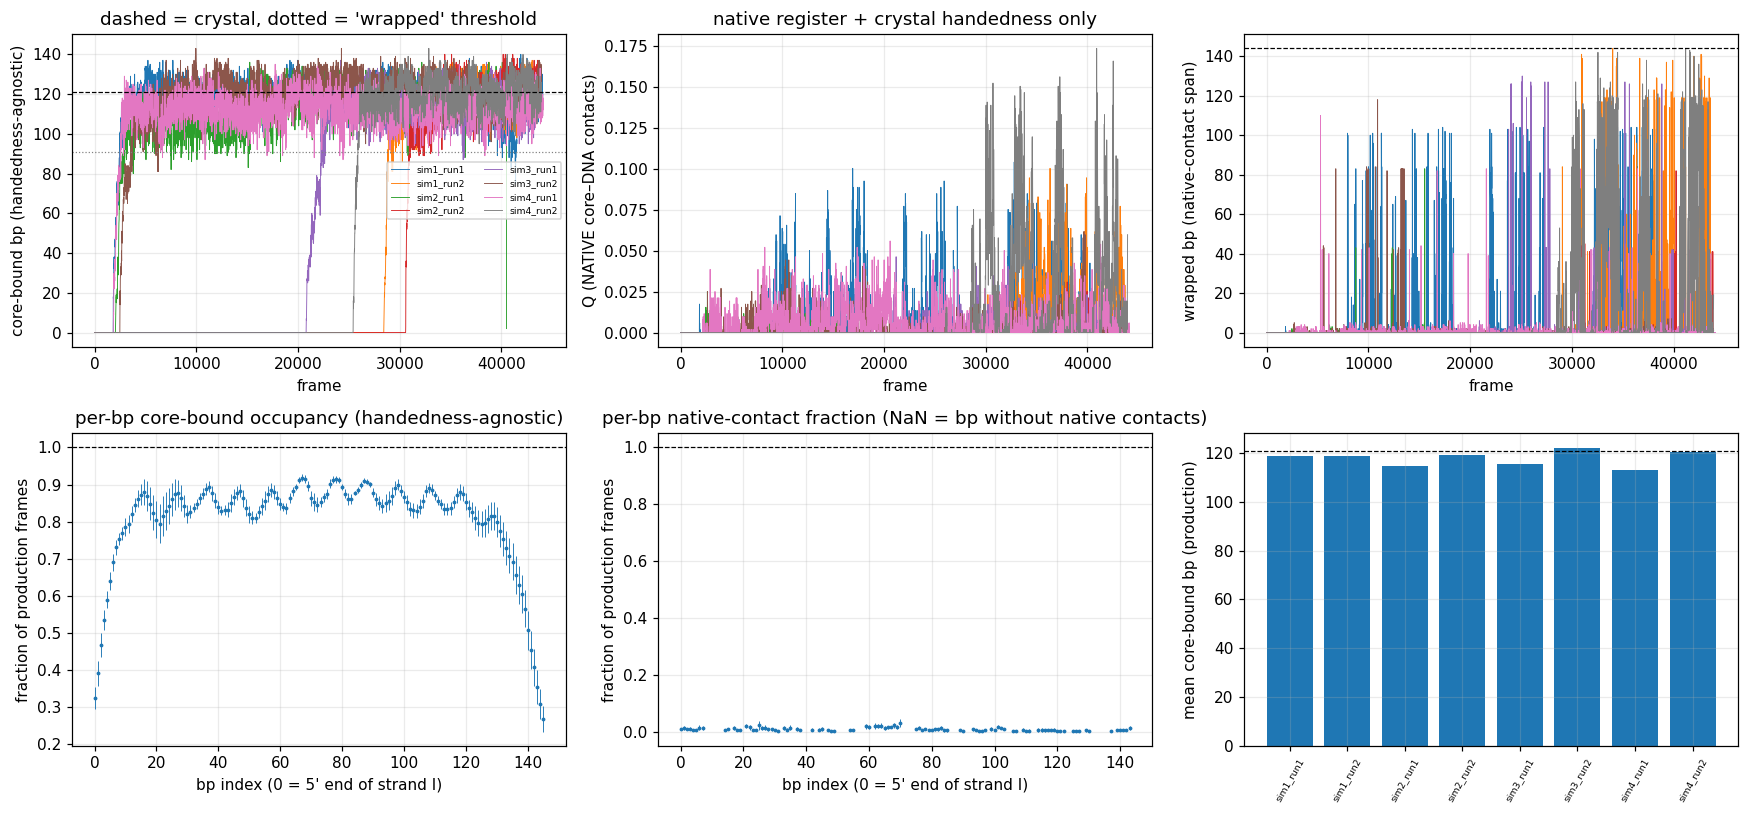

In [11]:
if ANALYSIS_COND and ANALYSIS_COND not in RES: print(f"ANALYSIS_COND={ANALYSIS_COND!r} not available (groups are created in §5b); using the first condition")
cond = ANALYSIS_COND if ANALYSIS_COND in RES else list(RES)[0]; Lw = REF["L"]; cr = CRYS[cond]
print(f"analysing: {cond}  (replicas: {list(RES[cond])})")
xl = "frame" if not FRAMES_TO_TIME else "time"
fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
for rep in RES[cond]:
    ax[0, 0].plot(tax(cond, rep, "n_close"), RES[cond][rep]["n_close"], lw=.6, label=rep)
    ax[0, 1].plot(tax(cond, rep, "Q"), RES[cond][rep]["Q"], lw=.6)
    ax[0, 2].plot(tax(cond, rep, "n_wrap"), RES[cond][rep]["n_wrap"], lw=.6)
ax[0, 0].axhline(cr["n_close"], c="k", ls="--", lw=.8); ax[0, 0].axhline(WRAP_FRAC_MIN * cr["n_close"], c="gray", ls=":", lw=.8)
ax[0, 0].set(xlabel=xl, ylabel="core-bound bp (handedness-agnostic)", title="dashed = crystal, dotted = 'wrapped' threshold"); ax[0, 0].legend(fontsize=6, ncol=2)
ax[0, 1].set(xlabel=xl, ylabel="Q (NATIVE core–DNA contacts)", title="native register + crystal handedness only")
ax[0, 2].axhline(cr["n_wrap"], c="k", ls="--", lw=.8); ax[0, 2].set(xlabel=xl, ylabel="wrapped bp (native-contact span)")
for a, nm, ttl in ((ax[1, 0], "bp_close", "per-bp core-bound occupancy (handedness-agnostic)"), (ax[1, 1], "bp_frac", "per-bp native-contact fraction (NaN = bp without native contacts)")):
    m, e = mean_sem(np.array([pmean(cond, r, nm) for r in RES[cond]]))
    a.errorbar(range(Lw), m, e, fmt=".", ms=3, lw=.6); a.axhline(1, c="k", ls="--", lw=.8)
    a.set(xlabel="bp index (0 = 5' end of strand I)", ylabel="fraction of production frames", title=ttl)
reps = list(RES[cond]); ax[1, 2].bar(range(len(reps)), [np.nanmean(prod(cond, r, "n_close")) for r in reps]); ax[1, 2].axhline(cr["n_close"], c="k", ls="--", lw=.8)
ax[1, 2].set_xticks(range(len(reps))); ax[1, 2].set_xticklabels(reps, rotation=60, fontsize=6); ax[1, 2].set(ylabel="mean core-bound bp (production)")
plt.tight_layout()
print("per-replica means (production window):")
print(pd.DataFrame({r: dict(n_close=np.mean(prod(cond, r, "n_close")), u5c=np.mean(prod(cond, r, "u5c")), u3c=np.mean(prod(cond, r, "u3c")),
                            n_wrap_c=np.mean(prod(cond, r, "n_wrap_c")), Q_native=np.mean(prod(cond, r, "Q")), n_wrap_native=np.mean(prod(cond, r, "n_wrap")),
                            dna_rg=np.mean(prod(cond, r, "dna_rg"))) for r in RES[cond]}).T.round(2))
print(f"crystal: n_close={cr['n_close']} u5c={cr['u5c']} u3c={cr['u3c']} n_wrap_c={cr['n_wrap_c']} | native n_wrap={cr['n_wrap']} | DNA Rg of a wrapped nucleosome ≈ 44-45 Å")

**Experimental comparison — wrapping / breathing**

| Simulation quantity | Experimental counterpart | Caveat |
|---|---|---|
| Reference geometry: on the 2CV5 CG structure this notebook gets n_wrap(native) = 144, n_close = 121, wrapping angle ≈ 646° (1.80 turns) — see the printed `CRYSTAL reference` line | crystal structures: Luger *et al.* 1997 *Nature* 389:251; Davey *et al.* 2002 *JMB* 319:1097; Tsunaka *et al.* 2005 *NAR* 33:3424 (= 2CV5, your source) | The crystal is the target, not an independent measurement of solution behaviour. Use the printed crystal values as the reference; the often-quoted "1.65 turns" is counted differently from the bp-centre angle computed here. |
| Per-bp contact occupancy (high in the centre, lower toward the ends) | End-to-dyad gradient of site accessibility: Polach & Widom 1995 *JMB* 254:130; Anderson & Widom 2000 *JMB* 296:979; Li & Widom 2004 *NSMB* 11:763 | Compare the *shape*, not the absolute value. |
| Wrapped bp, unwrapped length at each end (`u5c`, `u3c`) | Spontaneous end unwrapping (smFRET / restriction accessibility): Li *et al.* 2005 *NSMB* 12:46; Koopmans *et al.* 2007; Gansen *et al.* 2009 *PNAS* | Only ~10–20 bp at each end unwrap appreciably in the experiments; CG time scales are not real time. `u5c/u3c` count from the first/last core-bound bp (contact-free stretches inside the wrapped region do not count as unwrapped). |

*Citations are quoted from memory/your original notebook and have not been checked against the papers — verify before use.*

## 5b. Handedness of the wrapped DNA (all replicas)
Per analysed frame, the bp-centre path between the first and last core-bound bp is fitted with a helix **about its own axis** (PCA axis + circle fit, independent of any reference frame): signed pitch > 0 = right-handed, < 0 = left-handed; frames need ≥ `HAND_MIN_BP` bp and a span ≥ `HAND_MIN_SPAN`° to be classified, and |pitch| < `HAND_MIN_PITCH` is "ambiguous". The crystal is classified with the same function and must come out **LEFT** (printed below) — if it does not, the classifier is broken. A secondary, independent test compares the bp path with the crystal path after rigid superposition with and without allowing a mirror image (`hand_shape`, reported as *shape agrees*); it only gives a verdict when the DNA path resembles the crystal path to within `SHAPE_MAX`. Replica verdict: RIGHT / LEFT if ≥ 90 % of the classified wrapped frames agree, else MIXED. `switches_R_L` counts handedness changes along the trajectory.

[baseline] crystal 2CV5, same classifier: signed pitch -21.5 Å/turn, span 647° -> LEFT-handed (sign convention: > 0 right-handed; the crystal must come out LEFT)

[baseline] handedness of the wrapped DNA, production window:
          frames wrapped_frames  pct_right  pct_left pct_ambiguous switches_R_L median_pitch median_span shape_agrees_pct  Q_native first_classified wrapped_at_frame verdict
sim1_run1   3525           3359  88.627568  9.556416      1.816017            7    27.929842  584.869006            100.0  0.009866                R             2460   RIGHT
sim1_run2   1505            213      100.0       0.0           0.0            0     3.506273   90.533269          98.4375  0.015076                R            28890   RIGHT
sim2_run1   3241           2315  99.956803  0.043197           0.0            1    32.032343   565.76335            100.0   0.00018                R             2980   RIGHT
sim2_run2   1302           1302        0.0     100.0           0.0            0 

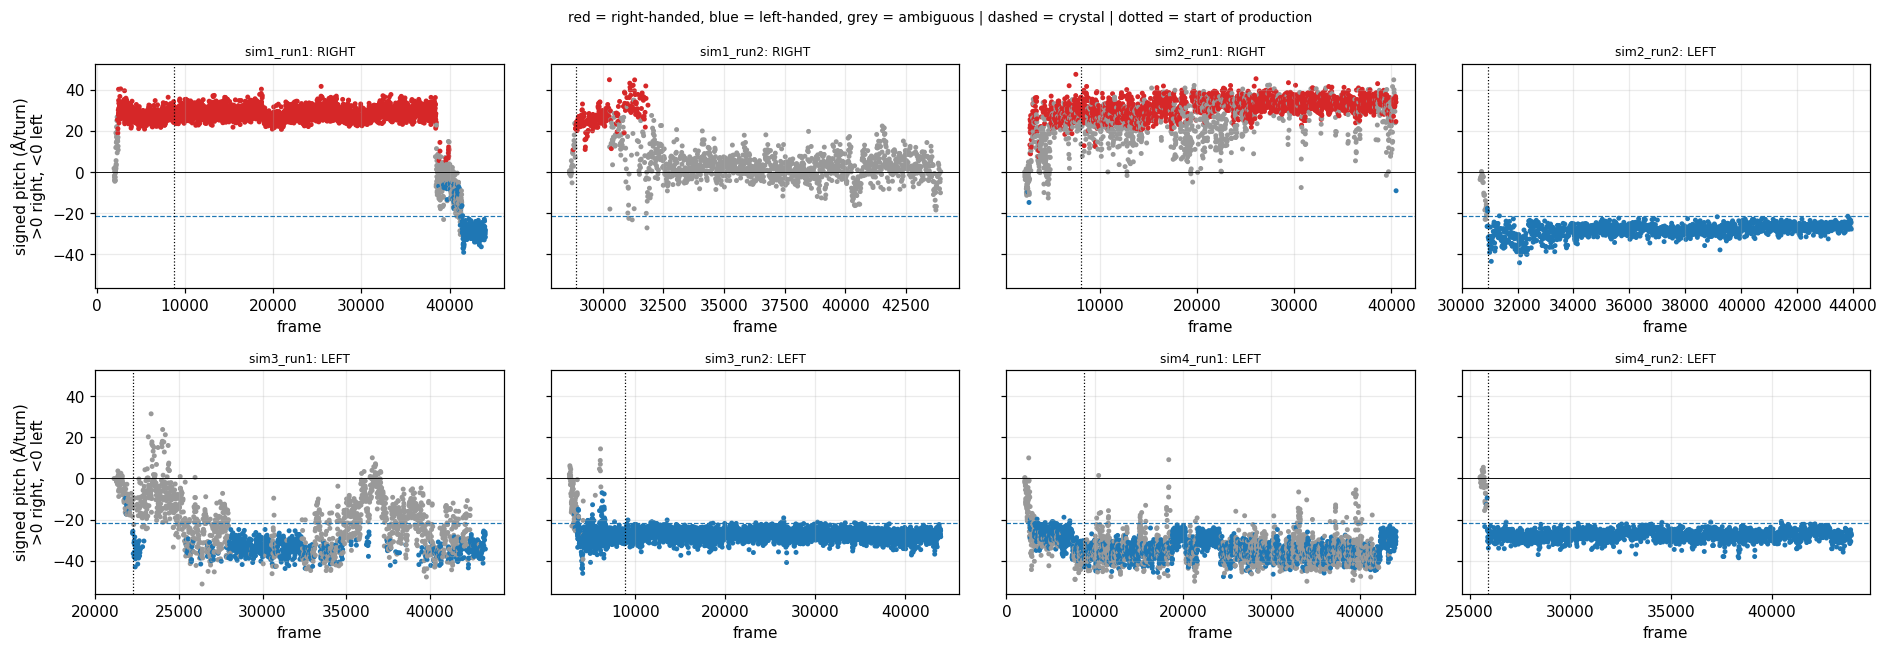

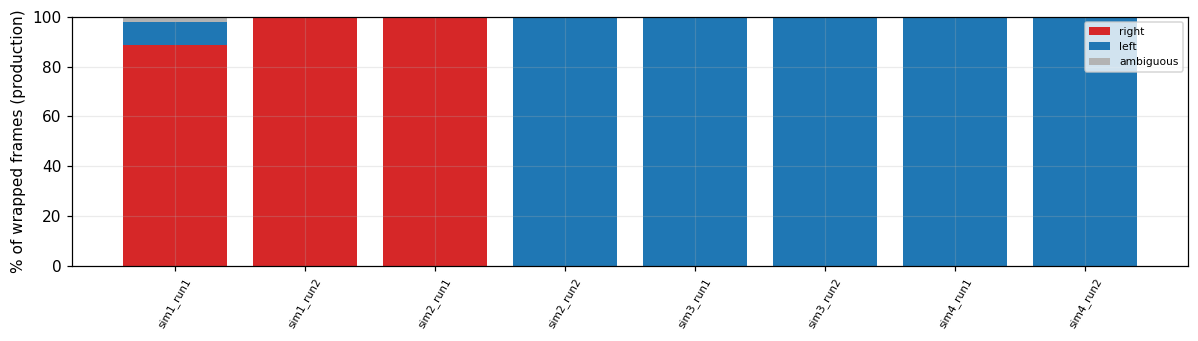

In [12]:
def _switches(h):
    s = h[(h == 1) | (h == -1)]
    return int((np.diff(s) != 0).sum()) if len(s) > 1 else 0

def handedness_table(cond, production=True):
    rows = {}
    for rep in RES[cond]:
        g = (lambda n: prod(cond, rep, n)) if production else (lambda n: RES[cond][rep][n])
        h, hs, hp = g("hand"), g("hand_shape"), g("hand_pitch")
        nR, nL, nA = int((h == 1).sum()), int((h == -1).sum()), int((h == 0).sum()); nW = nR + nL + nA
        fR = nR / max(nR + nL, 1)
        verdict = "no wrapped frames" if nR + nL == 0 else ("RIGHT" if fR >= 0.9 else ("LEFT" if fR <= 0.1 else "MIXED"))
        good = h[(h == 1) | (h == -1)]; first = "-" if len(good) == 0 else ("R" if good[0] == 1 else "L")
        both = ((h == 1) | (h == -1)) & ((hs == 1) | (hs == -1))
        rows[rep] = dict(frames=len(h), wrapped_frames=nW, pct_right=100 * nR / max(nW, 1), pct_left=100 * nL / max(nW, 1),
                         pct_ambiguous=100 * nA / max(nW, 1), switches_R_L=_switches(h),
                         median_pitch=np.nanmedian(hp) if np.isfinite(hp).any() else np.nan,
                         median_span=np.nanmedian(g("hand_span")) if np.isfinite(g("hand_span")).any() else np.nan,
                         shape_agrees_pct=100 * (h[both] == hs[both]).mean() if both.any() else np.nan,
                         Q_native=np.nanmean(g("Q")) if len(h) else np.nan, first_classified=first,
                         wrapped_at_frame=PROD_START[(cond, rep)][1], verdict=verdict)
    return pd.DataFrame(rows).T

for cd in [c for c in RES if "[" not in c]:
    cr = CRYS[cd]
    print(f"[{cd}] crystal 2CV5, same classifier: signed pitch {cr['hand_pitch']:+.1f} Å/turn, span {cr['hand_span']:.0f}° -> "
          f"{'RIGHT' if cr['hand_pitch'] > 0 else 'LEFT'}-handed (sign convention: > 0 right-handed; the crystal must come out LEFT)")
    T = handedness_table(cd)
    print(f"\n[{cd}] handedness of the wrapped DNA, production window:")
    print(T.round(1).to_string())
    print("\nwhole trajectory (including assembly; first_classified = handedness the DNA has when it first wraps):"); print(handedness_table(cd, production=False)[["wrapped_at_frame", "first_classified", "wrapped_frames", "pct_right", "pct_left", "pct_ambiguous", "switches_R_L", "verdict"]].round(1).to_string())
    print("\nverdict counts:", T["verdict"].value_counts().to_dict())
    reps = list(RES[cd]); ncol = min(4, len(reps)); nrow = int(np.ceil(len(reps) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(4.3 * ncol, 3.0 * nrow), squeeze=False, sharey=True)
    for a, rep in zip(axs.ravel(), reps):
        p, h = RES[cd][rep]["hand_pitch"], RES[cd][rep]["hand"]
        col = np.where(h == 1, "tab:red", np.where(h == -1, "tab:blue", "0.6"))
        a.scatter(tax(cd, rep, "hand_pitch"), p, c=col, s=5)
        a.axhline(0, c="k", lw=.6); a.axhline(cr["hand_pitch"], c="tab:blue", ls="--", lw=.8)
        a.axvline(PROD_START[(cd, rep)][0] * (FRAMES_TO_TIME or 1), c="k", ls=":", lw=.8)
        a.set_title(f"{rep}: {T.loc[rep, 'verdict']}", fontsize=8); a.set(xlabel=xl)
    for a in axs[:, 0]: a.set_ylabel("signed pitch (Å/turn)\n>0 right, <0 left")
    fig.suptitle("red = right-handed, blue = left-handed, grey = ambiguous | dashed = crystal | dotted = start of production", fontsize=9)
    plt.tight_layout()
    fig2, a2 = plt.subplots(figsize=(1.0 * len(reps) + 3, 3.2))
    x = np.arange(len(reps)); R_, L_, A_ = T["pct_right"].values.astype(float), T["pct_left"].values.astype(float), T["pct_ambiguous"].values.astype(float)
    a2.bar(x, R_, color="tab:red", label="right"); a2.bar(x, L_, bottom=R_, color="tab:blue", label="left"); a2.bar(x, A_, bottom=R_ + L_, color="0.7", label="ambiguous")
    a2.set_xticks(x); a2.set_xticklabels(reps, rotation=60, fontsize=7); a2.set(ylabel="% of wrapped frames (production)"); a2.legend(fontsize=7)
    plt.tight_layout()

GROUPS = {}     # group name -> parent condition
def split_by_verdict(cd):
    """If the replicas of condition `cd` differ in handedness, create pseudo-conditions '<cd>[RIGHT]', '<cd>[LEFT]', '<cd>[MIXED]'
    (sharing the same data) so that §5–§10 can be run separately per group: set ANALYSIS_COND = '<cd>[RIGHT]' and re-run from §5."""
    T = handedness_table(cd); verd = {v: [r for r in RES[cd] if T.loc[r, "verdict"] == v] for v in T["verdict"].unique() if v != "no wrapped frames"}
    if len(verd) < 2: print(f"[{cd}] all classified replicas agree ({', '.join(verd) or 'none wrapped'}): no split needed"); return
    for v, reps in verd.items():
        name = f"{cd}[{v}]"
        for D in (RES, FRM, INFO): D[name] = {r: D[cd][r] for r in reps}
        STATIC[name], CRYS[name], GROUPS[name] = STATIC[cd], CRYS[cd], cd
        for r in reps: PROD_START[(name, r)] = PROD_START[(cd, r)]
        print(f"[{cd}] created group {name!r}: {reps}")
    print("-> set ANALYSIS_COND to one of these and re-run §5 and §6–§10 to analyse that group on its own")
for cd in [c for c in RES if "[" not in c]: split_by_verdict(cd)

**Experimental comparison — handedness**

* Every nucleosome crystal structure (Luger 1997, Davey 2002, Tsunaka 2005) has **left-handed** DNA superhelix. A right-handed wrapped state is therefore *not* comparable to the experimental nucleosome; report it as a property of the model (e.g. wrapping driven by electrostatics without any term that selects the crystal handedness), not as a nucleosome observable.
* If replicas differ (RIGHT in some, LEFT in others) the handedness is set by the assembly pathway/initial condition; do not pool such replicas in §6–§10 — analyse them separately. `Q_native` is expected to be non-zero only in LEFT frames with crystal register.
* The own-axis pitch is biased low by ~10 % for a non-integer number of turns; only the **sign** is used for classification.

## 6. Site exposure (the direct analogue of restriction-enzyme accessibility) and F(N_wrap)
A site of length *w* bp, starting *s* bp from a DNA end, is "exposed" when the unwrapped length at that end is ≥ *s + w*. Then K(s) = P_exposed / (1 − P_exposed) and ΔG(s) = −kT ln K(s).

crystal reference on the same definition: u5c=0, u3c=2, n_wrap_c=144


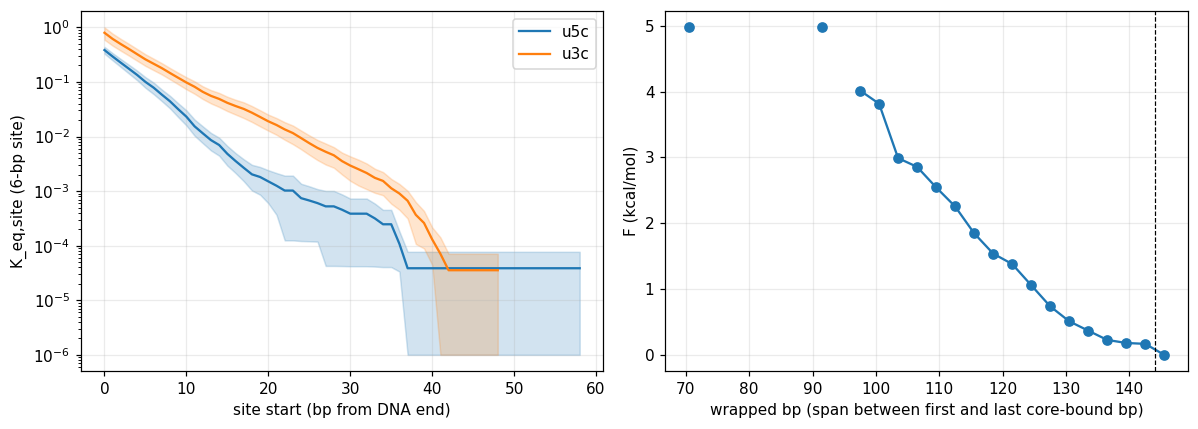

In [13]:
def site_exposure(cond, w=6, smax=60, ends=("u5c", "u3c")):
    """uses the handedness-agnostic unwrapped lengths u5c/u3c (use ends=("u5","u3") only for crystal-register wrapping)"""
    s_ = np.arange(0, smax); out = {}
    for end in ends:
        per_rep = []
        for r in RES[cond]:
            u = prod(cond, r, end); per_rep.append(np.array([(u >= s + w).mean() if len(u) else np.nan for s in s_]))
        out[end] = np.array(per_rep)
    return s_, out

s_, SE = site_exposure(cond)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for end, c in (("u5c", "C0"), ("u3c", "C1")):
    p = SE[end]; K = p / (1 - p + 1e-12); m, e = mean_sem(K)
    ok = np.isfinite(m) & (m > 0)
    ax[0].semilogy(s_[ok], m[ok], c=c, label=end); ax[0].fill_between(s_[ok], np.maximum(m - e, 1e-6)[ok], (m + e)[ok], color=c, alpha=.2)
ax[0].set(xlabel="site start (bp from DNA end)", ylabel="K_eq,site (6-bp site)"); ax[0].legend()
N = pooled(cond, "n_wrap_c")
if len(N):
    hist, edges = np.histogram(N, bins=np.arange(0, REF["L"] + 4, 3), density=True)
    F = -KT * np.log(np.where(hist > 0, hist, np.nan)); ax[1].plot(0.5 * (edges[1:] + edges[:-1]), F - np.nanmin(F), "o-")
ax[1].axvline(CRYS[cond]["n_wrap_c"], c="k", ls="--", lw=.8)
ax[1].set(xlabel="wrapped bp (span between first and last core-bound bp)", ylabel="F (kcal/mol)"); plt.tight_layout()
print(f"crystal reference on the same definition: u5c={CRYS[cond]['u5c']}, u3c={CRYS[cond]['u3c']}, n_wrap_c={CRYS[cond]['n_wrap_c']}")

**Experimental comparison — site exposure and F(N_wrap)**

* K(s) vs s is the quantity measured by Polach & Widom (1995), Anderson & Widom (2000) and Li & Widom (2004) with restriction enzymes at many positions: K falls steeply (orders of magnitude) from the DNA ends toward the dyad. Look up the table values in those papers and overlay them (ΔG = −kT ln K). Expect agreement in trend; the absolute magnitudes of a CG force field without tails/sequence-specific terms will differ.
* Force spectroscopy gives complementary information on the energetics of unwrapping (Brower-Toland *et al.* 2002 *PNAS* 99:1960; Mihardja *et al.* 2006 *PNAS* 103:15871; Hall *et al.* 2009 *NSMB* 16:124; Ngo *et al.* 2015 *Cell* 160:1135). These need a *pulling* simulation to compare quantitatively; F(N_wrap) from equilibrium runs is only a qualitative cross-check (barrier near the entry/exit region, multi-stage unwrapping).
* Caveat: a 4-day CG run may sample few deep-unwrapping events, so K for large s may be 0 (not measurable) — report which positions are statistically resolved.

## 7. Superhelix geometry and end-to-end distances

CRYSTAL (2CV5 bp centres, bound range): wrapping angle = 647° (1.80 turns), radius = 41.9 Å, |pitch| = 21.3 Å (PCA-axis pitch is biased low by ~10 %: compare with this crystal value only, not with literature)
core rmsd to crystal (Å): {'sim1_run1': 2.96, 'sim1_run2': 2.92, 'sim2_run1': 3.22, 'sim2_run2': 3.02, 'sim3_run1': 3.02, 'sim3_run2': 2.9, 'sim4_run1': 3.0, 'sim4_run2': 2.87}
FRET-pair bp distances (Å), mean ± sd (crystal in brackets): [((0, 145), np.float64(94.5), np.float64(25.9), '[63.4]'), ((10, 135), np.float64(83.1), np.float64(14.2), '[87.6]')]


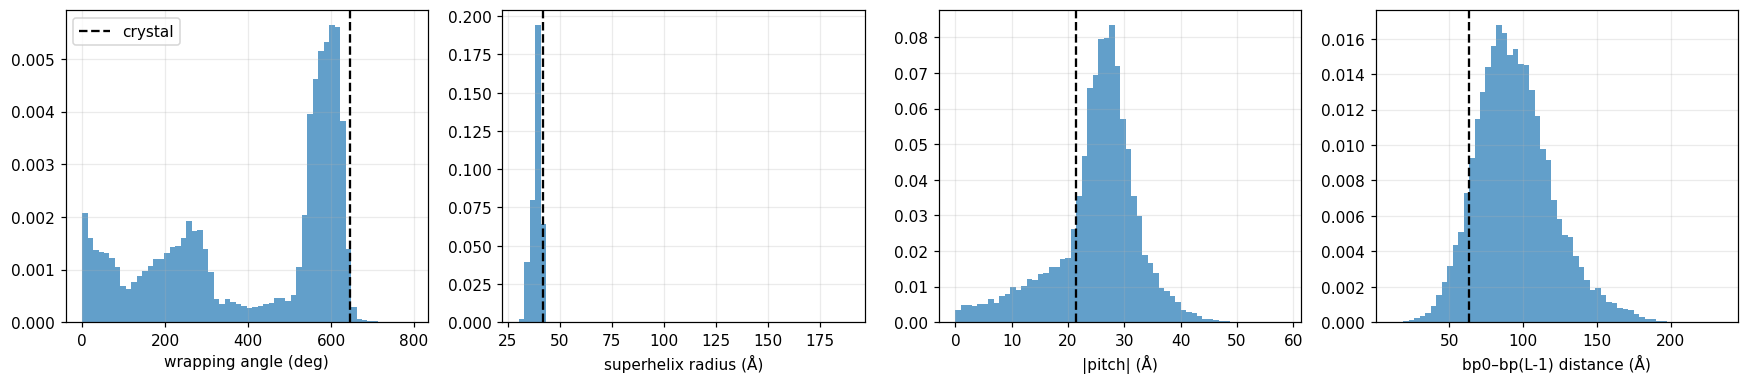

In [14]:
cr = CRYS[cond]
print(f"CRYSTAL (2CV5 bp centres, bound range): wrapping angle = {cr['wrap_angle']:.0f}° ({cr['wrap_angle']/360:.2f} turns), radius = {cr['radius']:.1f} Å, "
      f"|pitch| = {cr['pitch']:.1f} Å (PCA-axis pitch is biased low by ~10 %: compare with this crystal value only, not with literature)")
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, nm, ref_v, lab in zip(ax, ["wrap_angle", "radius", "pitch", "end_dist"], [cr["wrap_angle"], cr["radius"], cr["pitch"], cr["end_dist"]],
                             ["wrapping angle (deg)", "superhelix radius (Å)", "|pitch| (Å)", "bp0–bp(L-1) distance (Å)"]):
    x = pooled(cond, nm); x = x[np.isfinite(x)]
    if len(x): a.hist(x, bins=60, density=True, alpha=.7)
    a.axvline(ref_v, c="k", ls="--", label="crystal"); a.set(xlabel=lab)
ax[0].legend(); plt.tight_layout()
print("core rmsd to crystal (Å):", {r: round(float(np.mean(prod(cond, r, 'core_rmsd'))), 2) for r in RES[cond]})
fd = pooled(cond, "fret_dist")
print("FRET-pair bp distances (Å), mean ± sd (crystal in brackets):",
      [(FRET_PAIRS[k], round(fd[:, k].mean(), 1), round(fd[:, k].std(), 1), f"[{cr['fret_dist'][k]:.1f}]") for k in range(len(FRET_PAIRS))])

**Experimental comparison — geometry / FRET**

* Compare radius and pitch with the **crystal values printed above** (computed from your 2CV5 CG model with the same function). Literature numbers for the DNA superhelix (Luger 1997: pitch ≈ 24 Å, radius ≈ 42 Å — verify in the paper) differ from the PCA-axis values because that pitch is biased low by ~10 %.
* The geometry is evaluated on the handedness-agnostic bound range and in the crystal frame; for a right-handed wrapped state `radius`, `wrap_angle` and `end_dist` remain meaningful, but the superhelix is the mirror image of the crystal one.
* End-to-end / FRET-pair distances: smFRET on labelled nucleosomes (Li & Widom 2005; Koopmans 2007; Gansen 2009 — pick the paper whose dye positions you want to mimic and set `FRET_PAIRS`). Convert distance to efficiency with the dye's Förster radius **R0** (E = 1/(1+(r/R0)^6)); dye linkers add several Å of uncertainty, so use ensembles/thresholds (open vs closed), not single numbers.

## 8. Ion atmosphere: excess ions, charge neutralisation, Mg²⁺ preference
Γ_i(r) = N_i(<r) − ρ_i,bulk · V(<r), with *r* = distance to the nearest bead of the complex and ρ_bulk measured beyond R_MAX (so box-size depletion is accounted for). Shell volumes V(<r) are computed **per frame**. Model charges: phosphate −0.6 e, K/R +1, D/E −1, His +1 (assumed); the box is neutral with these (checked in §2). For a neutral box Σ q·Γ → −Q_complex at large r automatically, so the ratio to the complex charge is a sanity check; the informative quantities are the *split* between species and the radial profile.

ion frames skipped (sampling cube does not fit into the box, i.e. extended DNA before wrapping): {'sim1_run1': 12, 'sim1_run2': 235, 'sim2_run1': 18, 'sim2_run2': 290, 'sim3_run1': 175, 'sim3_run2': 19, 'sim4_run1': 13, 'sim4_run2': 190}
bulk concentrations (M), measured beyond R_MAX: {'K': np.float64(0.0501), 'Cl': np.float64(0.066), 'Mg': np.float64(0.0079)}
Excess ions per nucleosome at r = 50.0 Å  (n = 8 replicas):
        mean   sem
K      3.97  0.46
Cl     4.17  0.64
Mg    13.08  0.18
Σ qΓ  25.98  0.16
model charges: DNA -174.0 e, histone +148.0 e, complex -26.0 e
atmosphere charge / |complex net charge|        = 1.00   (-> 1 for a neutral box at large r; a sanity check, not a result)
atmosphere charge / |DNA phosphate charge|      = 0.15   (compare with free-DNA / ion-counting numbers)
charge from cation accumulation: 30.1 e ; from anion depletion: -4.2 e


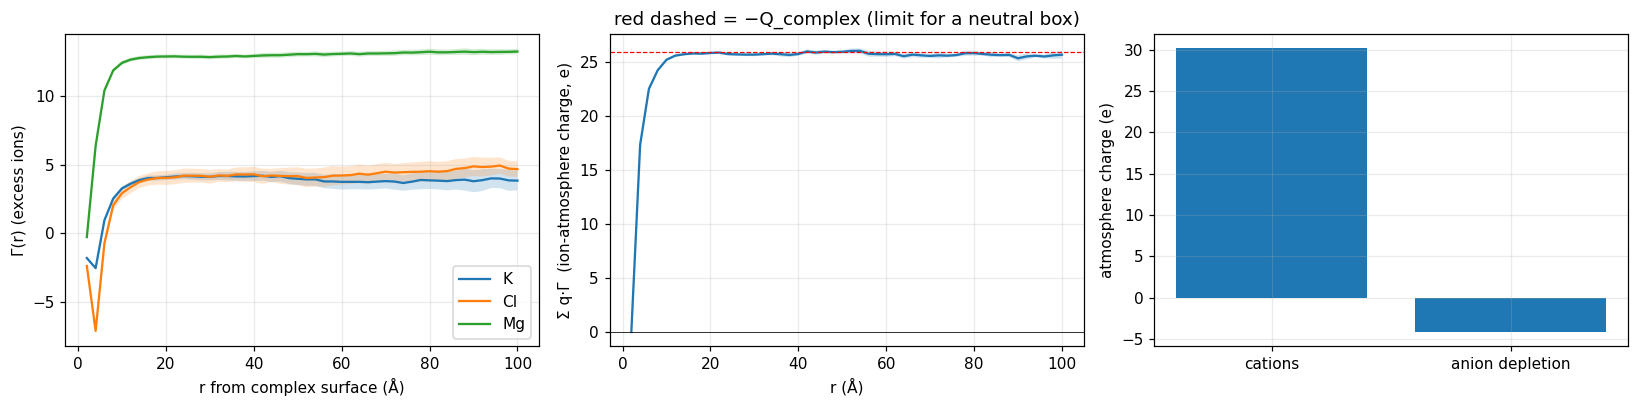

In [15]:
Sx = STATIC[cond]
IONS = [k for k in ION_RESNAMES if any(f"gam_{k}" in RES[cond][r] for r in RES[cond])]
_skipped = {r: INFO[cond][r]["ion_skipped"] for r in RES[cond]}
print("ion frames skipped (sampling cube does not fit into the box, i.e. extended DNA before wrapping):", _skipped)
reps_i = [r for r in RES[cond] if IONS and f"gam_{IONS[0]}" in RES[cond][r] and len(prod(cond, r, f"gam_{IONS[0]}")) > 0]
if not reps_i:
    print("no ion data in the production window (no box, or every ion frame skipped)")
else:
    rr = EDGES[1:]                       # upper edge of each shell (Å)
    G = {k: np.array([pmean(cond, r, f"gam_{k}") for r in reps_i]) for k in IONS}   # reps × bins
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for k in IONS:
        m, e = mean_sem(G[k]); ax[0].plot(rr, m, label=k); ax[0].fill_between(rr, m - e, m + e, alpha=.2)
    net = sum(ION_Q[k] * G[k] for k in IONS); m, e = mean_sem(net)
    ax[1].plot(rr, m); ax[1].fill_between(rr, m - e, m + e, alpha=.2); ax[1].axhline(0, c="k", lw=.5); ax[1].axhline(-Sx["Q_complex"], c="r", ls="--", lw=.8)
    ax[0].set(xlabel="r from complex surface (Å)", ylabel="Γ(r) (excess ions)"); ax[0].legend()
    ax[1].set(xlabel="r (Å)", ylabel="Σ q·Γ  (ion-atmosphere charge, e)", title="red dashed = −Q_complex (limit for a neutral box)")
    b = {k: np.nanmean([np.nanmean(prod(cond, r, f"bulk_M_{k}")) for r in reps_i]) for k in IONS}
    print("bulk concentrations (M), measured beyond R_MAX:", {k: round(v, 4) for k, v in b.items()})
    ip = int(np.argmin(abs(rr - R_PLATEAU))); sem = lambda x: x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan
    tab = pd.DataFrame({k: dict(zip(["mean", "sem"], [G[k][:, ip].mean(), sem(G[k][:, ip])])) for k in IONS}).T
    tab.loc["Σ qΓ"] = [net[:, ip].mean(), sem(net[:, ip])]
    print(f"Excess ions per nucleosome at r = {R_PLATEAU} Å  (n = {len(reps_i)} replicas):\n", tab.round(2))
    nm = net[:, ip].mean()
    print(f"model charges: DNA {Sx['Q_dna']:+.1f} e, histone {Sx['Q_histone']:+.1f} e, complex {Sx['Q_complex']:+.1f} e")
    print(f"atmosphere charge / |complex net charge|        = {nm/abs(Sx['Q_complex']):.2f}   (-> 1 for a neutral box at large r; a sanity check, not a result)")
    print(f"atmosphere charge / |DNA phosphate charge|      = {nm/abs(Sx['Q_dna']):.2f}   (compare with free-DNA / ion-counting numbers)")
    # share of the compensation from cation gain vs anion loss (both are positive contributions to the atmosphere charge)
    cat = sum(ION_Q[k] * G[k][:, ip].mean() for k in IONS if ION_Q[k] > 0)
    an = sum(ION_Q[k] * G[k][:, ip].mean() for k in IONS if ION_Q[k] < 0)
    print(f"charge from cation accumulation: {cat:.1f} e ; from anion depletion: {an:.1f} e")
    ax[2].bar(["cations", "anion depletion"], [cat, an]); ax[2].set_ylabel("atmosphere charge (e)"); plt.tight_layout()

**Experimental comparison — ion counting**

* Gebala, Johnson, Narlikar & Herschlag, *eLife* 2019;8:e44993 measured the ion atmosphere of nucleosomes by ion counting. Their conclusions you can test qualitatively: (i) the nucleosome keeps a strong negative electrostatic field although its net charge is roughly halved relative to free DNA; (ii) charge compensation comes mainly from **cation accumulation**, with anion exclusion contributing less; (iii) the nucleosome attracts the divalent cation (Mg²⁺) preferentially over monovalent ions. Get the measured excess-ion numbers and the salt conditions from the paper's figures/tables before overlaying — they used Na⁺/Mg²⁺ (not K⁺) and a specific nucleosome construct.
* Free-DNA benchmark for the same quantities: Bai, Greenfeld, Travers & Herschlag, *JACS* 2007, 129:14981 (ion counting on a short DNA duplex). Running the same analysis on a bare-DNA simulation gives the nucleosome/free-DNA comparison that Gebala et al. make.
* Caveat: the simulation uses a dielectric-scaled, implicit-water model with bare-charge point ions, so compare the *ordering and trends* (Mg²⁺ ≫ K⁺ per unit charge, cation-dominated neutralisation), and quote numbers with the plateau radius stated.
* Charges in this model: phosphate −0.6 e (TIS), so the DNA charge is −174 e, not −290 e; compare per-phosphate numbers with that in mind.

## 9. Local Mg²⁺ along the DNA vs. crystallographic metal sites

red lines = bp coordinating crystallographic Mn²⁺ (2CV5): [12, 25, 67, 75, 107, 120, 133] | coordinated atoms: ['N7', 'O6']
local [Mg] (M) around base beads:  Mn-coordinating nucleotides 0.074 | all guanines 0.073 | all bases 0.076 | bulk 0.0079
(compare Mn sites with ALL GUANINES, not with all bases: the sites are on guanines, so that is the fair control)


/tmp/ipykernel_267299/52080951.py:28: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, 0) if len(a) else np.full(RES[cond][rep][name].shape[1:], np.nan)
/tmp/ipykernel_267299/52080951.py:31: RuntimeWarning: Mean of empty slice
  x = np.asarray(x); return np.nanmean(x, 0), np.nanstd(x, 0, ddof=1) / np.sqrt(max(len(x), 2)) if len(x) > 1 else np.zeros_like(np.nanmean(x, 0))
/home/feynman/miniconda3/envs/venv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


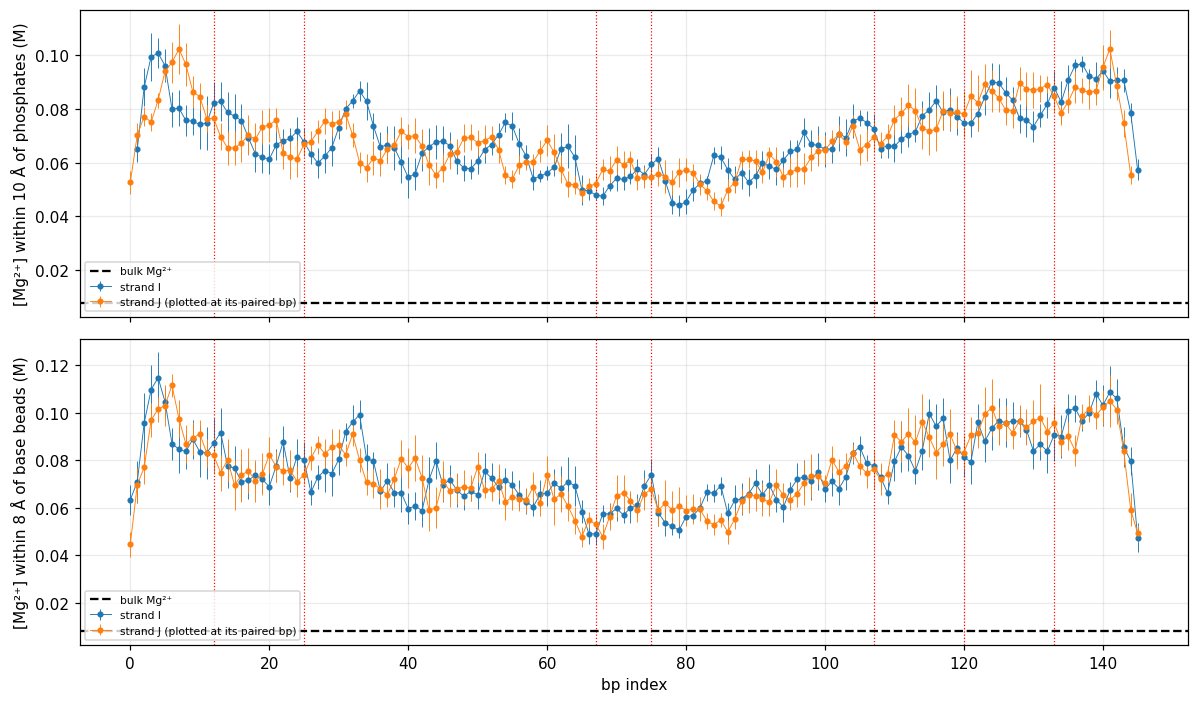

In [16]:
Lb = REF["L"]; mg = "Mg" if any("ploc_Mg" in RES[cond][r] for r in RES[cond]) else None
reps_m = [r for r in RES[cond] if mg and "ploc_Mg" in RES[cond][r] and len(prod(cond, r, "ploc_Mg")) > 0]
if reps_m:
    conv = lambda x, R: x * 1660.539 / (4 / 3 * np.pi * R ** 3)       # ions per sphere -> M
    ploc = np.array([pmean(cond, r, "ploc_Mg") for r in reps_m]); bloc = np.array([pmean(cond, r, "bloc_Mg") for r in reps_m])
    mp, ep = mean_sem(conv(ploc, R_LOC)); mb, eb = mean_sem(conv(bloc, R_BASE_LOC))
    bulk = np.nanmean([np.nanmean(prod(cond, r, "bulk_M_Mg")) for r in reps_m])
    fig, axs = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
    for ax_, m_, e_, nm_, Rr in ((axs[0], mp, ep, "phosphates", R_LOC), (axs[1], mb, eb, "base beads", R_BASE_LOC)):
        ax_.errorbar(np.arange(Lb), m_[:Lb], e_[:Lb], fmt=".-", lw=.6, label="strand I")
        ax_.errorbar(Lb - 1 - np.arange(Lb), m_[Lb:], e_[Lb:], fmt=".-", lw=.6, label="strand J (plotted at its paired bp)")
        for s in REF["mn_sites"]: ax_.axvline(s["bp"], c="r", ls=":", lw=.8)
        ax_.axhline(bulk, c="k", ls="--", label="bulk Mg²⁺")
        ax_.set(ylabel=f"[Mg²⁺] within {Rr:.0f} Å of {nm_} (M)"); ax_.legend(fontsize=7)
    axs[1].set(xlabel="bp index"); plt.tight_layout()
    print("red lines = bp coordinating crystallographic Mn²⁺ (2CV5):", sorted({s['bp'] for s in REF['mn_sites']}), "| coordinated atoms:", sorted({s['atom'] for s in REF['mn_sites']}))
    # the Mn2+ ions sit on base atoms (N7/O6 of guanine): compare base-bead-local [Mg] at those nucleotides with ALL guanines and ALL bases
    base_of = np.empty(2 * Lb, dtype="<U1")
    for b_ in REF["dna"]:
        if b_["bead"] == "B": base_of[b_["strand"] * Lb + b_["nt"]] = b_["base"]
    site_idx = [s["strand"] * Lb + s["nt"] for s in REF["mn_sites"]]; G_idx = np.where(base_of == "G")[0]
    cb = conv(bloc, R_BASE_LOC).mean(0)
    print(f"local [Mg] (M) around base beads:  Mn-coordinating nucleotides {np.nanmean(cb[site_idx]):.3f} | all guanines {np.nanmean(cb[G_idx]):.3f} | all bases {np.nanmean(cb):.3f} | bulk {bulk:.4f}")
    print("(compare Mn sites with ALL GUANINES, not with all bases: the sites are on guanines, so that is the fair control)")
else:
    print("no Mg data in the production window")

**Experimental comparison — metal binding sites**

* Crystallography: 2CV5 contains 9 Mn²⁺ ions (1 on a histone chain, 8 near the DNA chains); 7 of them are within 3.2 Å of a DNA atom and **all 7 coordinate base atoms (guanine N7, one O6)**, none a phosphate. Davey 2002 (1KX5) likewise places Mg²⁺/Mn²⁺ on the DNA. Your CG DNA has no base atoms, so the notebook uses the **base bead** (centre of mass of the base) as a proxy and compares the local Mg²⁺ at the Mn-coordinating nucleotides with *all guanines* (the fair control, since the sites are on guanines). Treat agreement as suggestive, not site-specific validation (crystal contacts, Mn²⁺ ≠ Mg²⁺, 100 K, packing).
* The comparison is by *sequence position* (nucleotide index), so it remains valid for a wrapped state with a different register or handedness.
* Global level: the Mg²⁺ enrichment relative to bulk compares with ion-counting results above.

## 10. Mg²⁺ scan summary (fill `mg_mM` in `CONDITIONS` and add one condition per concentration)

In [17]:
def summarize(cond):
    rows = {}
    for r in RES[cond]:
        h = prod(cond, r, "hand"); nrl = (h == 1).sum() + (h == -1).sum()
        d = dict(n_close=np.nanmean(prod(cond, r, "n_close")), n_wrap_c=np.nanmean(prod(cond, r, "n_wrap_c")), Q_native=np.nanmean(prod(cond, r, "Q")),
                 end_dist=np.nanmean(prod(cond, r, "end_dist")), wrap_angle=np.nanmean(prod(cond, r, "wrap_angle")),
                 frac_right=(h == 1).sum() / nrl if nrl else np.nan)
        for k in ION_RESNAMES:
            if f"gam_{k}" in RES[cond][r]:
                ip = int(np.argmin(abs(EDGES[1:] - R_PLATEAU)))
                g = prod(cond, r, f"gam_{k}")
                d[f"Gamma_{k}@{R_PLATEAU:.0f}"] = np.nanmean(g[:, ip]) if len(g) else np.nan
        rows[r] = d
    return pd.DataFrame(rows).T

summary = {c: summarize(c) for c in RES}
SUM = pd.concat({c: pd.DataFrame({"mean": s.mean(), "sem": s.std(ddof=1) / np.sqrt(len(s))}).T for c, s in summary.items()})
print(SUM.round(3))
xs = [(CONDITIONS[c]["mg_mM"], c) for c in RES if "[" not in c and CONDITIONS[c]["mg_mM"] is not None]
if len(xs) > 1:
    xs.sort(); cols = ["Q_native", "n_close", "end_dist", "frac_right"] + [c for c in summary[xs[0][1]].columns if c.startswith("Gamma_Mg")]
    fig, ax = plt.subplots(1, len(cols), figsize=(4 * len(cols), 3.4))
    for a, col in zip(np.atleast_1d(ax), cols):
        a.errorbar([x for x, _ in xs], [summary[c][col].mean() for _, c in xs],
                   [summary[c][col].std(ddof=1) / np.sqrt(len(summary[c])) for _, c in xs], fmt="o-"); a.set(xlabel="[MgCl2] (mM)", ylabel=col)
    plt.tight_layout()

                      n_close  n_wrap_c  Q_native  end_dist  wrap_angle  \
baseline        mean  117.902   136.452     0.008    95.014     396.065   
                sem     1.091     0.784     0.003     3.026      70.259   
baseline[RIGHT] mean  117.508   137.360     0.008    86.099     288.008   
                sem     1.395     0.579     0.004     3.245     136.924   
baseline[LEFT]  mean  118.139   135.907     0.008   100.362     460.899   
                sem     1.647     1.192     0.004     1.844      73.450   

                      frac_right  Gamma_K@50  Gamma_Cl@50  Gamma_Mg@50  
baseline        mean       0.363       3.974        4.167       13.085  
                sem        0.177       0.457        0.643        0.181  
baseline[RIGHT] mean       0.967       3.818        4.139       13.081  
                sem        0.032       0.593        1.033        0.280  
baseline[LEFT]  mean       0.000       4.067        4.183       13.087  
                sem        0.000    

**Experimental comparison — Mg²⁺ dependence**

* Ion counting (Gebala 2019): Mg²⁺ binding per nucleosome as a function of Mg²⁺ in a monovalent background → compare Γ_Mg(c) directly (same axes).
* Chromatin compaction/self-association vs. Mg²⁺ (e.g. Schwarz & Hansen 1994 *JBC* 269:16284; Allahverdi *et al.* 2011 *NAR* 39:1680; Korolev, Nordenskiöld and co-workers): arrays fold and nucleosome core particles aggregate at low-mM Mg²⁺. A mononucleosome simulation cannot reproduce inter-nucleosome compaction, but the *Mg²⁺-dependent screening of DNA–DNA/DNA–histone electrostatics* (Γ_Mg, entry/exit-DNA distance, end unwrapping) is the single-particle precursor — state it as such.
* Keep the monovalent background fixed across the scan and use ≥ 4–5 Mg²⁺ concentrations spanning 0–10 mM (the experimental transition region).

**Not included on purpose** (no direct experimental observable): Mg²⁺ bridges, bridge–wrapping correlations, Mg²⁺ residence times. Report them only as mechanistic predictions, clearly labelled as such.

## 11. Add your own analysis

In [18]:
# Template: copy, rename, re-run the "Run" cell (set FORCE_RECOMPUTE = True once so the cache is rebuilt).
@observable(every=1)
def obs_example(ctx, S):
    core_rg = np.sqrt(((ctx["core"] - ctx["core"].mean(0))**2).sum(1).mean())
    return dict(core_rg=core_rg)
# Then plot with:  pooled(cond, "core_rg")   /   prod(cond, rep, "core_rg")   /   rep_means(cond, "core_rg")
# ...and add an "Experimental comparison" markdown cell below it before it goes into the paper.